# Week 3 assignment: The OLS Trial
**Ioannis Tzalas | MSc Banking and Finance | September 2026**

Continuation of Weeks 1 and 2: **SPY, EUR/USD, BTC, GLD, ETH**. All calculations below use the unchanged Week 2 cleaned panel. GLD and ETH are my chosen assets.

**Course source verified:** Task 1 audits the actual `agent_draft_factor_model` from the supplied lecturer notebook and reproduces its saved Cell 8 AAPL row on its deterministic synthetic fallback. The five-asset tasks use the unchanged real Week 2 panel. The course's diagnostic, rolling-beta, Chow, ADF and audit functions are embedded below and reused or extended with explicitly described guards. The course's synthetic demonstration is kept separate from the real assignment universe.

The explanations are an evidence-based draft for the student to review and adapt to their own understanding. No email submission or publication has been performed.

## Pre-registered stability design (specified before fitting any regression)
**Break date: 2020-03-11**, the WHO pandemic declaration. Dates strictly before it form the first sample; this date and later dates form the second. The pandemic changed liquidity, policy responses and risk appetite across this mixed universe, providing an external economic reason to test joint coefficient stability. I use the course's **1% Chow cutoff**, not a break selected by searching the largest statistic. The cutoff reduces false positives; it does not cure the test's constant-variance assumption. A HAC interaction Wald test is included as a sensitivity check. Rolling betas use trailing 252-observation CAPM windows.

Sources: supplied `FinTechCourse_W3_Theory_new.tex` and `FinTechCourse_W3_Presentation_new.tex`; [WHO pandemic history](https://www.who.int/europe/emergencies/situations/covid-19).

In [1]:
import io, base64, gzip, json, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.regression.rolling import RollingOLS
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.spines.top': False, 'axes.spines.right': False})
OUTPUT = Path.cwd()
(OUTPUT / 'results').mkdir(exist_ok=True)
(OUTPUT / 'charts').mkdir(exist_ok=True)
interpretations = {}
BREAK = pd.Timestamp('2020-03-11')
ASSETS = ['SPY', 'EUR/USD', 'BTC', 'GLD', 'ETH']
# Embedded, frozen inputs make this notebook runnable offline and independently of its folder.
EMBEDDED = {'W2_cleaned_panel.csv': '...', 'factor_source_prices.csv': '...', 'french_daily_decimal.csv': '...'}
def read_frozen(name):
    raw = gzip.decompress(base64.b64decode(EMBEDDED[name]))
    return pd.read_csv(io.BytesIO(raw), index_col=0, parse_dates=True)
prices = read_frozen('W2_cleaned_panel.csv')[ASSETS]
proxy_prices = read_frozen('factor_source_prices.csv')
french = read_frozen('french_daily_decimal.csv')
assert hashlib.sha256(gzip.decompress(base64.b64decode(EMBEDDED['W2_cleaned_panel.csv']))).hexdigest() == 'bb07558003eb93f9eb02278b0f174d92e4dd6c5852d402275d623971239fd116'
assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert not prices.isna().any().any() and (prices > 0).all().all()
assert (prices.index.dayofweek < 5).all()
print(f'Week 2 input: {len(prices):,} prices, {prices.index.min().date()} to {prices.index.max().date()}')
print('Input checksum, missingness, ordering, positive prices and weekday calendar: PASS')
print('Versions:', platform.python_version(), pd.__version__, np.__version__, statsmodels.__version__, scipy.__version__)


Week 2 input: 2,218 prices, 2017-11-09 to 2026-09-14
Input checksum, missingness, ordering, positive prices and weekday calendar: PASS
Versions: 3.13.7 3.0.3+juno 2.4.6+juno 0.14.6+juno 1.18.0+juno


## Calendar, returns, and factor conventions
The presentation specifies MKT = SPY minus the risk-free return, SMB = IWM minus SPY, and HML = IWD minus IWF. I use decimal **log returns** for the factor models, matching the course notebook Cell 4. Log-return spreads are educational approximations to portfolio simple returns; the bonus compares these proxies against genuine simple-return research factors and discloses that convention difference. I first intersect **prices** on their dates and then calculate returns. Thus Monday BTC changes span the same retained date endpoints as the equity returns, rather than comparing a one-day Sunday-to-Monday crypto return with a Friday-to-Monday equity return.

`^IRX` quotes an annualized yield in percentage points; the daily approximation is the contemporaneous retained date's yield / 100 / 252, matching Cell 4. It is an educational discount-yield proxy, not a precise Treasury holding-period return. This contemporaneous convention reproduces the course; shifting the yield to tomorrow, as in its draft, is look-ahead. For a live trading forecast the lagged available cash quote would be the safer policy. The 252 convention is used consistently for annualization; weekend cash accrual is not modelled separately. ETF spreads receive no extra risk-free subtraction, because their two legs cancel cash. Yahoo factor ETF prices were downloaded with `auto_adjust=True`; the original Week 2 SPY prices are retained unchanged. Frozen sources and their checksums are in `data/manifest.json`. Different downloads may revise historical adjusted prices.

These daily observations also have different venue close times. Date alignment eliminates row errors but does not synchronize information arrival, so coefficients describe daily date-matched association, not causal or trading signals.

In [2]:
common = prices.index.intersection(proxy_prices.dropna(subset=['IWM','IWD','IWF','^IRX']).index)
p = prices.loc[common]
etf = proxy_prices.loc[common, ['IWM','IWD','IWF']]
r = np.log(p).diff()
e = np.log(etf).diff()
rf = proxy_prices.loc[common, '^IRX'] / 100 / 252
factors = pd.DataFrame({'MKT': r.SPY-rf, 'SMB': e.IWM-r.SPY, 'HML': e.IWD-e.IWF, 'RF': rf})
panel = r.join(factors).dropna()
assert len(panel) == len(p)-1
assert np.isfinite(panel.to_numpy()).all()
LAGS = int(np.floor(4*(len(panel)/100)**(2/9)))
print(f'Model sample: {len(panel):,} common returns, {panel.index.min().date()} to {panel.index.max().date()}, HAC lags={LAGS}')
print('Price dates lost at factor join:', len(prices)-len(p))
display(panel.head())
panel.to_csv(OUTPUT/'results'/'model_input_decimal_returns.csv')


Model sample: 2,217 common returns, 2017-11-10 to 2026-09-14, HAC lags=7
Price dates lost at factor join: 0


,SPY,EUR/USD,BTC,GLD,ETH,MKT,SMB,HML,RF
Date,,,,,,,,,
2017-11-10,-0.000310,0.004300,-0.076400,-0.008222,-0.069790,-0.000358,-0.000440,-0.002119,0.000048
2017-11-13,0.000929,0.001224,-0.008901,0.001485,0.056716,0.000882,-0.000657,-0.000362,0.000047
2017-11-14,-0.002325,0.000327,0.011559,0.002059,0.063948,-0.002374,-0.000407,-0.002544,0.000049
2017-11-15,-0.005018,0.010908,0.097529,-0.001235,-0.012740,-0.005067,0.001043,0.002736,0.000049
2017-11-17,0.005522,-0.001308,0.052386,0.011872,-0.002893,0.005473,0.013656,-0.001319,0.000049


## Task 1 - Actual lecturer draft audit and corrected factor_model_v1()
The audit below quotes the supplied course notebook's Cell 16 (physical cell index 27). Line numbers refer to that cell, including its three header lines. Its saved Cell 8 AAPL row is generated by the **seed-42 synthetic fallback**, with 3,132 log-return observations from 2014-09-18 through 2026-09-18. I regenerate that same fallback locally without any download and keep it separate from the real five-asset Week 2 panel.

### Original source, with exact cell line numbers


```python
01 # ============================================================
02 # Cell 16 — DO NOT TRUST: agent draft v0 of a factor-model estimator
03 # ============================================================
04 def agent_draft_factor_model(px: pd.DataFrame, irx: pd.Series, asset: str) -> pd.Series:
05     '''Three-factor model for `asset` from the price panel. (Agent draft — under review.)'''
06     r_asset = px[asset].pct_change()                                 # asset returns
07     r_f     = (irx / 100 / 252).shift(-1)                            # daily risk-free rate, lined up
08     r_fac   = np.log(px[["spy", "iwm", "iwd", "iwf"]]).diff()        # factor-ETF returns
09     F_ = pd.DataFrame({"MKT": r_fac["spy"],
10                        "SMB": r_fac["iwm"] - r_fac["spy"],
11                        "HML": r_fac["iwd"] - r_fac["iwf"]})
12     d_  = F_.join((r_asset - r_f).rename("y"), how="inner").dropna()
13     fit = sm.OLS(d_["y"], d_[["MKT", "SMB", "HML"]]).fit()
14     out = fit.params.copy()
15     out["alpha_ann_%"]     = 100 * (d_["y"] - fit.fittedvalues).mean() * np.sqrt(252)
16     out["resid_vol_ann_%"] = 100 * np.sqrt(fit.ssr / len(d_)) * 252
17     out["t_MKT"]           = fit.tvalues["MKT"]
18     return out
19 
20 print("AGENT DRAFT v0 — AAPL three-factor model (numbers NOT to be trusted):")
21 print(agent_draft_factor_model(px, irx, "aapl").round(4).to_string())
22 print("\nCompare with Cell 8's AAPL row. Then find out why they differ — there are at least five reasons.")
```

### Bugs and principles
| Line(s) | Actual mistake | Principle violated / correction |
|---|---|---|
| 6 and 8 | Simple asset returns vs log factor returns | Same return convention on both sides: use log asset returns as Cell 4 does. |
| 7 | Tomorrow's risk-free rate via shift(-1) | Week 2 information-set rule: future yields are unavailable today; remove the forward shift. |
| 9 | MKT is a raw market return | Define MKT as market excess return; subtract RF once. |
| 13 | Missing constant | Estimate the intercept explicitly; an uncentered fit cannot report Jensen's alpha reliably. |
| 15 | Residual mean substitutes for the intercept; multiplies by sqrt(252) | Alpha is the fitted constant, and its annual mean scales by 252. |
| 16 | Residual volatility multiplied by 252 | A standard deviation scales by sqrt(252); use residual degrees of freedom n-k for its estimated scale. |
| 13 and 17 | Classical covariance / t-statistic | Daily-return inference requires Newey-West HAC covariance, with the stated lag rule. |

The ablation fixes exactly one issue at a time on an identical date sample while leaving every other draft mistake in place. Alpha residual-mean scaling and volatility horizon scaling are isolated separately. A separate row isolates the n-k residual-scale correction. Some effects are masked by other bugs, so these changes must not be added together. The risk-free timing error moves **nothing** in the lecturer's constant-2% synthetic yield, so I also measure it on the frozen real AAPL/IRX data, where yields vary.

In [3]:
def factor_model_v1(asset_return, factor_frame, lags=None):
    """Date-join decimal log returns; subtract RF once; intercept; HAC inference."""
    # Accept the original course's (price_panel, irx_yield, asset_name) signature too.
    if isinstance(asset_return,pd.DataFrame) and isinstance(factor_frame,pd.Series):
        px_,irx_,asset_name=asset_return,factor_frame,lags
        assert isinstance(asset_name,str), 'Third argument must be the asset column name'
        rr=np.log(px_).diff();rf_=(irx_/100/252).reindex(rr.index)
        ff=pd.DataFrame({'MKT':rr.spy-rf_,'SMB':rr.iwm-rr.spy,'HML':rr.iwd-rr.iwf,'RF':rf_})
        return factor_model_v1(rr[asset_name],ff)
    d = asset_return.rename('asset_return').to_frame().join(factor_frame[['MKT','SMB','HML','RF']], how='inner').dropna()
    assert d.index.is_unique and d.index.is_monotonic_increasing
    assert np.isfinite(d.to_numpy()).all()
    X = sm.add_constant(d[['MKT','SMB','HML']], has_constant='add')
    y = d.asset_return-d.RF
    q = int(np.floor(4*(len(d)/100)**(2/9))) if lags is None else int(lags)
    classical = sm.OLS(y, X).fit()
    hac = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags':q, 'use_correction':True}, use_t=False)
    return {'data':d, 'y':y, 'X':X, 'classical':classical, 'hac':hac, 'lags':q,
            'alpha_ann':float(hac.params['const']*252),
            'resid_vol_ann':float(np.std(hac.resid, ddof=X.shape[1])*np.sqrt(252))}


In [4]:
# Exact course functions, extracted without executing the notebook's downloads.
COURSE_FUNCTIONS = 'def diagnose(res) -> dict:\n    \'\'\'p-values of the four classical diagnostics on a fitted OLS result. Reports; judges nothing.\'\'\'\n    e = res.resid\n    return {"BP p":       het_breuschpagan(e, res.model.exog)[1],\n            "LB(ε) p":    acorr_ljungbox(e, lags=[10])["lb_pvalue"].iloc[0],\n            "LB(ε²) p":   acorr_ljungbox(e**2, lags=[10])["lb_pvalue"].iloc[0],\n            "JB p":       jarque_bera(e)[1],\n            "kurtosis":   stats.kurtosis(e, fisher=False)}\n\ndef rolling_beta(y, x, w=252):\n    \'\'\'β_t = Cov_t(y, x) / Var_t(x) over a trailing window — the OLS slope, window by window.\'\'\'\n    return y.rolling(w).cov(x) / x.rolling(w).var()\n\ndef chow_test(y, X, break_date):\n    \'\'\'Chow (1960): one pooled fit vs two sub-sample fits. Returns F, p and the two betas.\'\'\'\n    pre, post = y.index < break_date, y.index >= break_date\n    pooled, m1, m2 = sm.OLS(y, X).fit(), sm.OLS(y[pre], X[pre]).fit(), sm.OLS(y[post], X[post]).fit()\n    k_, n_ = X.shape[1], len(y)\n    F_ = ((pooled.ssr - m1.ssr - m2.ssr) / k_) / ((m1.ssr + m2.ssr) / (n_ - 2*k_))\n    return {"F": F_, "p": 1 - stats.f.cdf(F_, k_, n_ - 2*k_), "β before": m1.params.iloc[1], "β after": m2.params.iloc[1]}\n\ndef adf_row(s):\n    \'\'\'ADF with AIC lag selection. H0: unit root. p < 0.05 ⇒ stationary.\'\'\'\n    stat, p, lags, *_ = adfuller(s.dropna(), regression="c", autolag="AIC")\n    return {"ADF stat": stat, "p-value": p, "verdict": "stationary ✅" if p < 0.05 else "UNIT ROOT ⚠️"}\n\ndef audit_regression(y: pd.Series, X: pd.DataFrame, name: str, break_date=BREAK) -> bool:\n    \'\'\'Estimate, then put the result on trial. True only if every rule passes.\'\'\'\n    d  = pd.concat([y, X], axis=1).dropna(); y_, X_ = d.iloc[:, 0], sm.add_constant(d.iloc[:, 1:])\n    q  = int(np.floor(4 * (len(y_) / 100) ** (2 / 9)))\n    ols = sm.OLS(y_, X_).fit(); hac = ols.get_robustcov_results(cov_type="HAC", maxlags=q)\n    unit_roots = [c for c in d.columns if adf_row(d[c])["p-value"] >= 0.05]\n    chow = chow_test(y_, X_, break_date)\n    RULES = [("E1 no unit roots among the variables",               len(unit_roots) == 0),\n             ("E2 HAC standard errors reported",                     True),      # enforced by construction here\n             ("E3 alpha claimed only if HAC |t| > 2",                abs(ols.tvalues.iloc[0]) <= 2 or abs(hac.tvalues[0]) > 2),\n             ("E4 stable beta (Chow at pre-registered date, 1%)",    chow["p"] > 0.01)]\n    print(f"ANALYST AGENT — eval rules v0.1 on \'{name}\'   (T = {len(y_):,}, HAC lags = {q})")\n    print("=" * 62)\n    all_ok = True\n    for label, ok in RULES:\n        all_ok &= ok; print(f"  {\'✅ PASS\' if ok else \'❌ FAIL\'}  {label}")\n    if unit_roots: print(f"           ↳ unit roots in: {\', \'.join(map(str, unit_roots))}")\n    print(f"           ↳ Chow F = {chow[\'F\']:.1f} (p = {chow[\'p\']:.1e}); β before/after = {chow[\'β before\']:.2f}/{chow[\'β after\']:.2f}")\n    if not unit_roots:\n        print(f"  disclosure: adj-R² = {ols.rsquared_adj:.3f}, α = {ols.params.iloc[0]*252:+.2%}/yr (t_HAC = {hac.tvalues[0]:.2f}), β = {ols.params.iloc[1]:.2f} (se_HAC = {hac.bse[1]:.3f})")\n    print("=" * 62)\n    print("VERDICT:", "ACCEPTED for reporting" if all_ok else "REJECTED — fix or report with caveats", "\\n")\n    return all_ok'
course_ns = {'np':np,'pd':pd,'sm':sm,'stats':stats,'plt':plt,'Path':Path,
             'het_breuschpagan':het_breuschpagan,'acorr_ljungbox':acorr_ljungbox,
             'jarque_bera':jarque_bera,'adfuller':adfuller,'BREAK':BREAK}
exec(COURSE_FUNCTIONS,course_ns)
course_diagnose=course_ns['diagnose']
course_rolling_beta=course_ns['rolling_beta']
course_chow_test=course_ns['chow_test']
course_adf_row=course_ns['adf_row']
course_audit_regression=course_ns['audit_regression']
# Regenerate the reference market with precisely the original seeded generator.
course_ns.update({'RNG':np.random.default_rng(42),'START':pd.Timestamp('2014-09-17'),
                  'END_SYN':pd.Timestamp('2026-09-18')})
exec('def garch_path(n, sig, alpha=0.07, beta=0.90, df=5):\n    \'\'\'Zero-mean shocks with volatility clustering (GARCH) and fat tails (Student-t): Week 1\'s stylized facts.\'\'\'\n    omega = sig**2 * (1 - alpha - beta)\n    z = RNG.standard_t(df, n) / np.sqrt(df / (df - 2))\n    s2, r = np.empty(n), np.empty(n); s2[0] = sig**2\n    for t in range(n):\n        if t: s2[t] = omega + alpha * r[t-1]**2 + beta * s2[t-1]\n        r[t] = np.sqrt(s2[t]) * z[t]\n    return r\n\ndef generate_synthetic_market():\n    bdays, alldays = pd.date_range(START, END_SYN, freq="B"), pd.date_range(START, END_SYN, freq="D")\n    nb, rf = len(bdays), 0.02 / 252\n    centred = lambda x, m: m + (x - x.mean())\n    mkt = centred(garch_path(nb, 0.18/np.sqrt(252), df=6), 0.07/252)    # 7% premium, 18% vol, clustered\n    smb = centred(0.005 * RNG.standard_normal(nb), 0.0)\n    hml = centred(0.005 * RNG.standard_normal(nb), 0.0)\n    down = np.maximum(-mkt, 0)                                            # residuals are noisier on market down days\n    TRUE = {  #  beta,   s,     h,    alpha/day, idio vol\n        "aapl": (1.20, -0.30, -0.40, 0.00020, 0.012),\n        "jpm":  (1.10,  0.00,  0.60, 0.00000, 0.010),\n        "ko":   (0.60, -0.30,  0.20, 0.00000, 0.008),\n        "gld":  (0.05,  0.00,  0.00, 0.00000, 0.009),\n    }\n    rets = {}\n    for stem, (b, s, h, a, sig) in TRUE.items():\n        eps = garch_path(nb, sig) * (1 + 30 * down); eps -= eps.mean()\n        rets[stem] = rf + a + b*mkt + s*smb + h*hml + eps\n    nz = lambda sig: sig * RNG.standard_normal(nb)                         # factor ETFs built from the factors\n    rets["spy"] = rf + mkt + nz(0.0005)\n    rets["iwm"] = rf + mkt + smb + nz(0.002)\n    rets["iwd"] = rf + mkt + 0.5*hml + nz(0.0015)\n    rets["iwf"] = rf + mkt - 0.5*hml + nz(0.0015)\n    btc = pd.Series(0.40/365 + garch_path(len(alldays), 0.035, df=4), index=alldays)   # every day\n    btc.loc[bdays] += np.where(bdays < BREAK, 0.10, 1.00) * mkt          # equity beta 0.1 → 1.0 at the break\n    S0 = {"spy": 200, "iwm": 110, "iwd": 100, "iwf": 90, "aapl": 25, "jpm": 60, "ko": 42, "gld": 117}\n    prices = {stem: pd.Series(S0[stem] * np.exp(np.cumsum(r)), index=bdays) for stem, r in rets.items()}\n    prices["btc"] = 450 * np.exp(btc.cumsum())\n    prices["irx"] = pd.Series(2.0, index=bdays)                          # T-bill yield in %, like ^IRX\n    return prices, TRUE',course_ns)
reference_prices,_ = course_ns['generate_synthetic_market']()
ref_px = pd.concat([reference_prices[a].rename(a) for a in ['spy','iwm','iwd','iwf','aapl','jpm','ko','gld']],axis=1).dropna()
ref_irx=reference_prices['irx'].ffill().reindex(ref_px.index).ffill()
ORIGINAL_DRAFT = 'def agent_draft_factor_model(px: pd.DataFrame, irx: pd.Series, asset: str) -> pd.Series:\n    \'\'\'Three-factor model for `asset` from the price panel. (Agent draft — under review.)\'\'\'\n    r_asset = px[asset].pct_change()                                 # asset returns\n    r_f     = (irx / 100 / 252).shift(-1)                            # daily risk-free rate, lined up\n    r_fac   = np.log(px[["spy", "iwm", "iwd", "iwf"]]).diff()        # factor-ETF returns\n    F_ = pd.DataFrame({"MKT": r_fac["spy"],\n                       "SMB": r_fac["iwm"] - r_fac["spy"],\n                       "HML": r_fac["iwd"] - r_fac["iwf"]})\n    d_  = F_.join((r_asset - r_f).rename("y"), how="inner").dropna()\n    fit = sm.OLS(d_["y"], d_[["MKT", "SMB", "HML"]]).fit()\n    out = fit.params.copy()\n    out["alpha_ann_%"]     = 100 * (d_["y"] - fit.fittedvalues).mean() * np.sqrt(252)\n    out["resid_vol_ann_%"] = 100 * np.sqrt(fit.ssr / len(d_)) * 252\n    out["t_MKT"]           = fit.tvalues["MKT"]\n    return out'
exec(ORIGINAL_DRAFT,course_ns)
agent_draft_factor_model=course_ns['agent_draft_factor_model']


In [5]:
def reference_inputs(px,irx,asset):
    ret=np.log(px).diff()
    rf=(irx/100/252).reindex(ret.index)
    ff=pd.DataFrame({'MKT':ret.spy-rf,'SMB':ret.iwm-ret.spy,'HML':ret.iwd-ret.iwf,'RF':rf})
    return ret[asset],ff
ref_return,ref_factors=reference_inputs(ref_px,ref_irx,'aapl')
reference=factor_model_v1(ref_px,ref_irx,'aapl')
ref_classical=sm.OLS(reference['y'],reference['X']).fit()
# Independent direct execution of Cell 8's mathematical specification.
cell8_model=sm.OLS(reference['y'],sm.add_constant(ref_factors[['MKT','SMB','HML']].dropna())).fit()
np.testing.assert_allclose(reference['hac'].params,cell8_model.params,rtol=1e-12,atol=1e-12)
assert len(reference['y'])==3132
# Saved Cell 8 numbers are rounded, so their tolerance is half the last displayed decimal.
checks=[('CAPM alpha %/yr',5.576,sm.OLS(reference['y'],sm.add_constant(ref_factors[['MKT']].dropna())).fit().params['const']*252*100,.0005),
 ('3F alpha %/yr',5.443,reference['alpha_ann']*100,.0005),
 ('MKT beta',1.212,reference['hac'].params.MKT,.0005),
 ('SMB loading',-.24,reference['hac'].params.SMB,.005),
 ('HML loading',-.39,reference['hac'].params.HML,.005),
 ('CAPM R2',.569,sm.OLS(reference['y'],sm.add_constant(ref_factors[['MKT']].dropna())).fit().rsquared,.0005),
 ('3F adjusted R2',.587,reference['hac'].rsquared_adj,.0005)]
verification=pd.DataFrame([{'quantity':q,'saved_Cell8':expected,'corrected':actual,'absolute_error':abs(actual-expected),'rounding_tolerance':tol,'PASS':abs(actual-expected)<=tol} for q,expected,actual,tol in checks])
assert verification.PASS.all()
display(verification)
verification.to_csv(OUTPUT/'results'/'task1_Cell8_AAPL_verification.csv',index=False)
# Saved Cell 16 draft output is also reproduced to verify the input fixture.
ref_px.to_csv(OUTPUT/'results'/'task1_course_reference_prices.csv')
ref_irx.to_csv(OUTPUT/'results'/'task1_course_reference_IRX.csv')
ref_baseline=agent_draft_factor_model(ref_px,ref_irx,'aapl')
for key,expected in {'MKT':1.2130,'SMB':-.2389,'HML':-.3903,'alpha_ann_%':.4586,'resid_vol_ann_%':295.4221,'t_MKT':65.8863}.items():
    assert abs(ref_baseline[key]-expected)<=.00005,(key,ref_baseline[key],expected)
print('Saved Cell 16 draft outputs reproduced within printed rounding: PASS')
print('Original draft baseline:',ref_baseline.to_dict())
# Every variant edits the actual source, not a substitute estimator.
mutations={
 'Log asset returns (line 6)':('.pct_change()', ').diff()'),
 'Remove future RF shift (line 7)':('.shift(-1)', ''),
 'Excess MKT (line 9)':('"MKT": r_fac["spy"]','"MKT": r_fac["spy"] - r_f'),
 'Add constant (line 13)':('d_[["MKT", "SMB", "HML"]]).fit()', 'sm.add_constant(d_[["MKT", "SMB", "HML"]])).fit()'),
 'Alpha horizon only (line 15)':('mean() * np.sqrt(252)','mean() * 252'),
 'Volatility horizon only (line 16)':('np.sqrt(fit.ssr / len(d_)) * 252','np.sqrt(fit.ssr / len(d_)) * np.sqrt(252)'),
 'Residual degrees of freedom (line 16)':('fit.ssr / len(d_)','fit.ssr / fit.df_resid'),
 'HAC inference (line 13/17)':(']).fit()', ']).fit(cov_type="HAC", cov_kwds={"maxlags":8}, use_t=False)')}
def audit_fixture(px,irx,asset):
    baseline=agent_draft_factor_model(px,irx,asset)
    valid=reference_inputs(px,irx,asset)[0].dropna().index[:-1]
    def source_run(source):
        # Force the common retained dates after the original join/dropna, preserving price/return construction.
        source=source.replace('fit = sm.OLS', 'd_ = d_.reindex(AUDIT_DATES).dropna()\n    fit = sm.OLS')
        ns=dict(course_ns);ns['AUDIT_DATES']=valid;exec(source,ns)
        return ns['agent_draft_factor_model'](px,irx,asset)
    baseline=source_run(ORIGINAL_DRAFT);rows=[]
    for name,(old,new) in mutations.items():
        source=ORIGINAL_DRAFT.replace('r_asset = px[asset].pct_change()', 'r_asset = np.log(px[asset]).diff()') if name.startswith('Log asset') else ORIGINAL_DRAFT.replace(old,new)
        got=source_run(source)
        rows.append({'fix_alone':name,'n_common':len(valid),'alpha_ann_pct':got['alpha_ann_%'],'MKT_beta':got.MKT,
          'resid_vol_ann_pct':got['resid_vol_ann_%'],'t_MKT_reported':got.t_MKT,
          'delta_alpha_pp':got['alpha_ann_%']-baseline['alpha_ann_%'],'delta_beta':got.MKT-baseline.MKT,
          'delta_resid_vol_pp':got['resid_vol_ann_%']-baseline['resid_vol_ann_%'],'delta_t_MKT':got.t_MKT-baseline.t_MKT})
    return pd.DataFrame(rows)
audit=audit_fixture(ref_px,ref_irx,'aapl')
display(audit);audit.to_csv(OUTPUT/'results'/'task1_actual_draft_single_fix_synthetic.csv',index=False)
real_px=proxy_prices.loc[p.index,['AAPL','IWM','IWD','IWF']].rename(columns={'AAPL':'aapl','IWM':'iwm','IWD':'iwd','IWF':'iwf'})
real_px['spy']=p.SPY;real_irx=proxy_prices.loc[p.index,'^IRX']
real_audit=audit_fixture(real_px,real_irx,'aapl')
display(real_audit);real_audit.to_csv(OUTPUT/'results'/'task1_actual_draft_single_fix_real_AAPL.csv',index=False)
# Corrected reference vs independent numpy least-squares, before interpreting inference.
manual=np.linalg.lstsq(reference['X'].to_numpy(),reference['y'].to_numpy(),rcond=None)[0]
np.testing.assert_allclose(manual,reference['hac'].params.to_numpy(),rtol=1e-10,atol=1e-12)
print('Corrected reference HAC lags:',reference['lags'])
print('Corrected annual residual volatility (%):',reference['resid_vol_ann']*100)
interpretations['task1']='Cell 8 verification: all seven printed AAPL quantities match within their published rounding tolerances, and the full coefficient vector agrees with direct OLS and independent numpy least-squares. The synthetic reference has annualized alpha {:.6f}%, MKT {:.6f}, SMB {:.6f}, HML {:.6f}, and adjusted R² {:.6f}. '.format(reference['alpha_ann']*100,*reference['hac'].params[['MKT','SMB','HML']],reference['hac'].rsquared_adj)
interpretations['task1']+='The tables quantify each single fix using the original draft. A delta in annual alpha or residual volatility is in percentage points; beta changes are dimensionless. On the synthetic fixture, removing the future-yield shift has zero effect because IRX is constant, whereas the real-data timing row measures its effect under changing yields. Adding the intercept alone makes the residual-mean alpha approximately zero while the annualization bug remains; this is why the complete correction uses the fitted constant rather than residual mean. HAC changes the reported market t-statistic but not the OLS coefficients, so a zero coefficient delta does not mean that inference was sound.'


,quantity,saved_Cell8,corrected,absolute_error,rounding_tolerance,PASS
0,CAPM alpha %/yr,5.576,5.575664,0.000336,0.0005,True
1,3F alpha %/yr,5.443,5.443040,0.000040,0.0005,True
2,MKT beta,1.212,1.212254,0.000254,0.0005,True
3,SMB loading,-0.240,-0.238344,0.001656,0.0050,True
4,HML loading,-0.390,-0.389813,0.000187,0.0050,True
5,CAPM R2,0.569,0.569248,0.000248,0.0005,True
6,3F adjusted R2,0.587,0.587115,0.000115,0.0005,True


Saved Cell 16 draft outputs reproduced within printed rounding: PASS
Original draft baseline: {'MKT': 1.2130016267498862, 'SMB': -0.2388740411278642, 'HML': -0.39027935814268416, 'alpha_ann_%': 0.4585862999736369, 'resid_vol_ann_%': 295.4220587018034, 't_MKT': 65.88625033419413}


,fix_alone,n_common,alpha_ann_pct,MKT_beta,resid_vol_ann_pct,t_MKT_reported,delta_alpha_pp,delta_beta,delta_resid_vol_pp,delta_t_MKT
0,Log asset returns (line 6),3131,1.935335e-01,1.212751,295.720215,65.806217,-0.265053,-0.000251,0.298156,-0.080033
1,Remove future RF shift (line 7),3131,4.585863e-01,1.213002,295.422059,65.886250,0.000000,0.000000,0.000000,0.000000
2,Excess MKT (line 9),3131,6.113857e-01,1.213013,295.491792,65.859496,0.152799,0.000012,0.069734,-0.026755
3,Add constant (line 13),3131,-6.468227e-13,1.212258,295.332261,65.827079,-0.458586,-0.000744,-0.089798,-0.059171
4,Alpha horizon only (line 15),3131,7.279832e+00,1.213002,295.422059,65.886250,6.821246,0.000000,0.000000,0.000000
5,Volatility horizon only (line 16),3131,4.585863e-01,1.213002,18.609840,65.886250,0.000000,0.000000,-276.812218,0.000000
6,Residual degrees of freedom (line 16),3131,4.585863e-01,1.213002,295.563691,65.886250,0.000000,0.000000,0.141633,0.000000
7,HAC inference (line 13/17),3131,4.585863e-01,1.213002,295.422059,61.720321,0.000000,0.000000,0.000000,-4.165929


,fix_alone,n_common,alpha_ann_pct,MKT_beta,resid_vol_ann_pct,t_MKT_reported,delta_alpha_pp,delta_beta,delta_resid_vol_pp,delta_t_MKT
0,Log asset returns (line 6),2216,1.759949e-01,1.104871,299.091435,47.098764,-0.287789,-0.000322,-0.700338,0.096328
1,Remove future RF shift (line 7),2216,4.638664e-01,1.105189,299.791282,47.002357,0.000083,-0.000004,-0.000491,-0.000080
2,Excess MKT (line 9),2216,6.450267e-01,1.105655,299.801418,46.999410,0.181243,0.000463,0.009645,-0.003027
3,Add constant (line 13),2216,-1.900531e-12,1.103865,299.701059,46.893825,-0.463784,-0.001327,-0.090714,-0.108612
4,Alpha horizon only (line 15),2216,7.362335e+00,1.105193,299.791773,47.002437,6.898552,0.000000,0.000000,0.000000
5,Volatility horizon only (line 16),2216,4.637835e-01,1.105193,18.885107,47.002437,0.000000,0.000000,-280.906667,0.000000
6,Residual degrees of freedom (line 16),2216,4.637835e-01,1.105193,299.994907,47.002437,0.000000,0.000000,0.203134,0.000000
7,HAC inference (line 13/17),2216,4.637835e-01,1.105193,299.791773,41.178083,0.000000,0.000000,0.000000,-5.824354


Corrected reference HAC lags: 8
Corrected annual residual volatility (%): 18.637673033022722


Cell 8 verification: all seven printed AAPL quantities match within their published rounding tolerances, and the full coefficient vector agrees with direct OLS and independent numpy least-squares. The synthetic reference has annualized alpha 5.443040%, MKT 1.212254, SMB -0.238344, HML -0.389813, and adjusted R² 0.587115. The tables quantify each single fix using the original draft. A delta in annual alpha or residual volatility is in percentage points; beta changes are dimensionless. On the synthetic fixture, removing the future-yield shift has zero effect because IRX is constant, whereas the real-data timing row measures its effect under changing yields. Adding the intercept alone makes the residual-mean alpha approximately zero while the annualization bug remains; this is why the complete correction uses the fitted constant rather than residual mean. HAC changes the reported market t-statistic but not the OLS coefficients, so a zero coefficient delta does not mean that inference was sound.

### Debugging log
I started by comparing the draft's return definitions with Cell 4 and found a simple-return dependent variable paired with log-return factors. Next I inspected the date transforms: `shift(-1)` reads tomorrow's yield, although the constant synthetic yield hides its numerical effect. I then traced the market column back to the excess-return equation and found that RF was subtracted from the asset but not from MKT. The missing `const` in the parameter names explained why the draft substituted a residual mean for a fitted alpha. I separated the incorrect mean and volatility horizon multipliers because one scales by 252 and the other by its square root. Finally I checked the covariance type and replaced the classical market t-statistic with HAC inference. After all fixes, the exact synthetic input gave the same coefficients, annual alpha and adjusted R² as Cell 8, and the saved rounded AAPL row matched.

**Output-only blind spot:** the forward risk-free shift is numerically invisible when the input yield is constant, so no test of those output numbers can catch it; agent supervision also needs source-level information-set checks and a varying-yield test fixture.

## Task 2 - CAPM and three-factor models
Each estimate uses the same business-day intersection and HAC covariance with Bartlett weights, a finite-sample correction, and q = floor(4(T/100)^(2/9)) lags. HAC inference uses the asymptotic normal reference distribution. Annual alpha and its SE are multiplied by 252, while the loadings and their SEs remain dimensionless. Dashes/NaNs for CAPM SMB/HML mean those regressors are absent.

Chosen-asset tests are two-sided at 5%: **H0: market beta = 1** and **H0: daily alpha = 0**. Tables state the null, statistic and decision before the p-value. Failure to reject is not proof of equality. Individual tests are not adjusted for multiplicity.

In [6]:
models = {a:factor_model_v1(panel[a],panel[['MKT','SMB','HML','RF']],LAGS) for a in ASSETS}
capms={};rows=[]
for a in ASSETS:
    y=panel[a]-panel.RF;X=sm.add_constant(panel[['MKT']])
    capms[a]=sm.OLS(y,X).fit(cov_type='HAC',cov_kwds={'maxlags':LAGS,'use_correction':True},use_t=False)
    for label,m in [('CAPM',capms[a]),('Three-factor',models[a]['hac'])]:
        rows.append({'asset':a,'model':label,'n':int(m.nobs),'alpha_ann_pct':m.params['const']*252*100,
          'alpha_HAC_se_pct':m.bse['const']*252*100,'MKT':m.params.MKT,'MKT_HAC_se':m.bse.MKT,
          'SMB':m.params.get('SMB',np.nan),'SMB_HAC_se':m.bse.get('SMB',np.nan),
          'HML':m.params.get('HML',np.nan),'HML_HAC_se':m.bse.get('HML',np.nan),
          'R2':m.rsquared,'adj_R2':m.rsquared_adj,'HAC_lags':LAGS})
estimates=pd.DataFrame(rows);display(estimates.round(5));estimates.to_csv(OUTPUT/'results'/'task2_estimates.csv',index=False)
tests=[]
for a in ['GLD','ETH']:
    for label,m in [('CAPM',capms[a]),('Three-factor',models[a]['hac'])]:
        for term,null in [('MKT',1),('const',0)]:
            t=(m.params[term]-null)/m.bse[term];pv=2*stats.norm.sf(abs(t))
            tests.append({'asset':a,'model':label,'H0':f'{term} = {null}','HAC_statistic':t,
                          'decision_5pct':'Reject H0' if pv<.05 else 'Do not reject H0','p_value':pv})
tests=pd.DataFrame(tests);display(tests);tests.to_csv(OUTPUT/'results'/'task2_chosen_asset_tests.csv',index=False)
text=[]
for a in ['GLD','ETH']:
    m=models[a]['hac'];b=m.params.MKT;lo,hi=m.conf_int().loc['MKT'];al=m.params['const']*252*100;alo,ahi=m.conf_int().loc['const']*252*100
    kind='gold exposure, with no corporate cash flows' if a=='GLD' else 'a high-volatility crypto asset with changing risk appetite exposure'
    text.append(f'**{a}.** The three-factor market loading is {b:.3f}, with HAC 95% interval [{lo:.3f}, {hi:.3f}]; SMB is {m.params.SMB:.3f} and HML is {m.params.HML:.3f}. Annualized alpha is {al:.2f}% with interval [{alo:.2f}%, {ahi:.2f}%], and adjusted R² is {m.rsquared_adj:.3f}. This describes {kind}. Equity size/value loadings measure covariance with ETF spreads, not literal firm size or book-to-market for this asset. The intervals and the stability results below limit any claim that a single pooled beta is an enduring asset characteristic.')
for a in ASSETS:
    c=capms[a];m=models[a]['hac'];text.append(f'{a}: annual alpha moves from {c.params["const"]*252*100:.2f}% (CAPM) to {m.params["const"]*252*100:.2f}% (three-factor), a change of {(m.params["const"]-c.params["const"])*252*100:.2f} percentage points; adjusted R² moves from {c.rsquared_adj:.3f} to {m.rsquared_adj:.3f}.')
text.append('A change in alpha reallocates the average return attributed to the intercept after controlling for the additional spread exposures; it does not prove that skill appeared or disappeared. For SPY the market factor is constructed from the same return, so its perfect fit is an algebraic control, not a discovery.')
text.append(f'**BTC and EUR/USD.** Their three-factor R² values are {models["BTC"]["hac"].rsquared:.3f} and {models["EUR/USD"]["hac"].rsquared:.3f}. Bitcoin prices depend on crypto-specific adoption, leverage and venue liquidity, while EUR/USD reflects relative monetary policy and currency demand. US equity ETF spreads leave many of those drivers outside the regression, and different closing times further weaken contemporaneous alignment. Low R² therefore describes limited equity-factor explanatory power, not a failure of the estimator or evidence of no risk.')
interpretations['task2']='\n\n'.join(text)


,asset,model,n,alpha_ann_pct,alpha_HAC_se_pct,MKT,MKT_HAC_se,SMB,SMB_HAC_se,HML,HML_HAC_se,R2,adj_R2,HAC_lags
0,SPY,CAPM,2217,0.00000,0.00000,1.00000,0.00000,NaN,NaN,NaN,NaN,1.00000,1.00000,7
1,SPY,Three-factor,2217,0.00000,0.00000,1.00000,0.00000,-0.00000,0.00000,0.00000,0.00000,1.00000,1.00000,7
2,EUR/USD,CAPM,2217,-2.73951,2.34179,0.01130,0.01147,NaN,NaN,NaN,NaN,0.00088,0.00043,7
3,EUR/USD,Three-factor,2217,-2.80446,2.33536,0.01478,0.01356,-0.01364,0.01481,0.00836,0.01483,0.00137,0.00001,7
4,BTC,CAPM,2217,13.13242,22.22685,1.02136,0.14168,NaN,NaN,NaN,NaN,0.08671,0.08629,7
5,BTC,Three-factor,2217,16.59434,22.09414,0.82391,0.17537,0.74249,0.13123,-0.48891,0.14265,0.10456,0.10335,7
6,GLD,CAPM,2217,9.44060,5.33888,0.10963,0.02645,NaN,NaN,NaN,NaN,0.01493,0.01448,7
7,GLD,Three-factor,2217,9.91213,5.34073,0.08635,0.02915,0.09652,0.04107,-0.05376,0.03873,0.01915,0.01782,7
8,ETH,CAPM,2217,4.39268,27.94259,1.46230,0.18072,NaN,NaN,NaN,NaN,0.10419,0.10379,7
9,ETH,Three-factor,2217,8.26845,27.86948,1.22870,0.22234,0.84728,0.16719,-0.59198,0.19269,0.11826,0.11706,7


,asset,model,H0,HAC_statistic,decision_5pct,p_value
0,GLD,CAPM,MKT = 1,-33.655977,Reject H0,2.549377e-248
1,GLD,CAPM,const = 0,1.768274,Do not reject H0,7.701513e-02
2,GLD,Three-factor,MKT = 1,-31.341394,Reject H0,1.274489e-215
3,GLD,Three-factor,const = 0,1.855949,Do not reject H0,6.346076e-02
4,ETH,CAPM,MKT = 1,2.558052,Reject H0,1.052604e-02
5,ETH,CAPM,const = 0,0.157204,Do not reject H0,8.750844e-01
6,ETH,Three-factor,MKT = 1,1.028577,Do not reject H0,3.036784e-01
7,ETH,Three-factor,const = 0,0.296685,Do not reject H0,7.667071e-01


**GLD.** The three-factor market loading is 0.086, with HAC 95% interval [0.029, 0.143]; SMB is 0.097 and HML is -0.054. Annualized alpha is 9.91% with interval [-0.56%, 20.38%], and adjusted R² is 0.018. This describes gold exposure, with no corporate cash flows. Equity size/value loadings measure covariance with ETF spreads, not literal firm size or book-to-market for this asset. The intervals and the stability results below limit any claim that a single pooled beta is an enduring asset characteristic.

**ETH.** The three-factor market loading is 1.229, with HAC 95% interval [0.793, 1.664]; SMB is 0.847 and HML is -0.592. Annualized alpha is 8.27% with interval [-46.35%, 62.89%], and adjusted R² is 0.117. This describes a high-volatility crypto asset with changing risk appetite exposure. Equity size/value loadings measure covariance with ETF spreads, not literal firm size or book-to-market for this asset. The intervals and the stability results below limit any claim that a single pooled beta is an enduring asset characteristic.

SPY: annual alpha moves from -0.00% (CAPM) to 0.00% (three-factor), a change of 0.00 percentage points; adjusted R² moves from 1.000 to 1.000.

EUR/USD: annual alpha moves from -2.74% (CAPM) to -2.80% (three-factor), a change of -0.06 percentage points; adjusted R² moves from 0.000 to 0.000.

BTC: annual alpha moves from 13.13% (CAPM) to 16.59% (three-factor), a change of 3.46 percentage points; adjusted R² moves from 0.086 to 0.103.

GLD: annual alpha moves from 9.44% (CAPM) to 9.91% (three-factor), a change of 0.47 percentage points; adjusted R² moves from 0.014 to 0.018.

ETH: annual alpha moves from 4.39% (CAPM) to 8.27% (three-factor), a change of 3.88 percentage points; adjusted R² moves from 0.104 to 0.117.

A change in alpha reallocates the average return attributed to the intercept after controlling for the additional spread exposures; it does not prove that skill appeared or disappeared. For SPY the market factor is constructed from the same return, so its perfect fit is an algebraic control, not a discovery.

**BTC and EUR/USD.** Their three-factor R² values are 0.105 and 0.001. Bitcoin prices depend on crypto-specific adoption, leverage and venue liquidity, while EUR/USD reflects relative monetary policy and currency demand. US equity ETF spreads leave many of those drivers outside the regression, and different closing times further weaken contemporaneous alignment. Low R² therefore describes limited equity-factor explanatory power, not a failure of the estimator or evidence of no risk.

## Task 3 - The residual trial and repair
Diagnostic nulls, all assessed at 5%: Breusch-Pagan **H0: constant conditional variance**; Ljung-Box residuals **H0: zero autocorrelation through lag 10**; Ljung-Box squared residuals **H0: zero squared-residual autocorrelation through lag 10**; Jarque-Bera **H0: normal residuals**. These are diagnostic flags, not a causal test of exogeneity. The same 10-lag diagnostic is used for each asset, independently of the HAC bandwidth.

SPY is an exact self-regression control: residual variance is numerical noise, so its residual diagnostics and intercept tests are reported as **not applicable** rather than interpreted as economic evidence.

In [7]:
def diagnose(model):
    m=model['classical'];eps=np.asarray(m.resid)
    if np.std(eps)<1e-12:
        return pd.DataFrame([{'test':t,'H0':h,'statistic':np.nan,'decision_5pct':'N/A: exact control','p_value':np.nan}
            for t,h in [('BP','Constant conditional variance'),('LB residual','No residual autocorrelation, lags 1-10'),('LB squared','No squared-residual autocorrelation, lags 1-10'),('JB','Normal residuals')]])
    original_diagnostics=course_diagnose(m)
    bp=het_breuschpagan(eps,m.model.exog)
    lb=acorr_ljungbox(eps,lags=[10],return_df=True).iloc[0]
    lb2=acorr_ljungbox(eps**2,lags=[10],return_df=True).iloc[0]
    jb=jarque_bera(eps)
    rows=[]
    for t,h,v,pv in [('BP','Constant conditional variance',bp[0],bp[1]),('LB residual','No residual autocorrelation, lags 1-10',lb.lb_stat,lb.lb_pvalue),('LB squared','No squared-residual autocorrelation, lags 1-10',lb2.lb_stat,lb2.lb_pvalue),('JB','Normal residuals',jb[0],jb[1])]:
        rows.append({'test':t,'H0':h,'statistic':v,'decision_5pct':'Reject H0' if pv<.05 else 'Do not reject H0','p_value':pv})
    result=pd.DataFrame(rows)
    np.testing.assert_allclose(result.p_value, [original_diagnostics[k] for k in ['BP p','LB(ε) p','LB(ε²) p','JB p']], atol=1e-14)
    return result
scoreboard=pd.concat([diagnose(models[a]).assign(asset=a) for a in ASSETS],ignore_index=True)
scoreboard=scoreboard[['asset','test','H0','statistic','decision_5pct','p_value']]
display(scoreboard);scoreboard.to_csv(OUTPUT/'results'/'task3_diagnostics.csv',index=False)
effects={'BP':('Changing variance alone does not bias OLS coefficients when the conditional mean is correctly specified and regressors are exogenous.','The homoskedastic covariance formula is invalid; HAC estimates a covariance that allows changing variance.'),
 'LB residual':('Serially dependent errors alone do not establish coefficient bias under exogeneity, but they warrant checking timing and omitted dynamics.','Independence-based standard errors can be too small or too large; HAC accounts for dependence through its bandwidth.'),
 'LB squared':('Volatility clustering alone does not bias the conditional-mean coefficients under exogeneity.','Classical constant-variance inference is unreliable; HAC provides asymptotic protection, not a model for volatility.'),
 'JB':('Non-normality alone does not imply biased OLS coefficients if the necessary moments and exogeneity hold.','Exact Gaussian small-sample t/F reasoning is unavailable; large-sample HAC inference still needs finite moments and regularity conditions.')}
interpretations['diagnostics']='\n\n'.join(f'**{a}, {t}:** {effects[t][0]} {effects[t][1]}' for a,t in scoreboard.loc[scoreboard.decision_5pct=='Reject H0',['asset','test']].itertuples(index=False,name=None))


,asset,test,H0,statistic,decision_5pct,p_value
0,SPY,BP,Constant conditional variance,NaN,N/A: exact control,NaN
1,SPY,LB residual,"No residual autocorrelation, lags 1-10",NaN,N/A: exact control,NaN
2,SPY,LB squared,"No squared-residual autocorrelation, lags 1-10",NaN,N/A: exact control,NaN
3,SPY,JB,Normal residuals,NaN,N/A: exact control,NaN
4,EUR/USD,BP,Constant conditional variance,17.614377,Reject H0,5.281950e-04
5,EUR/USD,LB residual,"No residual autocorrelation, lags 1-10",15.574025,Do not reject H0,1.124931e-01
6,EUR/USD,LB squared,"No squared-residual autocorrelation, lags 1-10",171.920126,Reject H0,1.110291e-31
7,EUR/USD,JB,Normal residuals,441.889686,Reject H0,1.108853e-96
8,BTC,BP,Constant conditional variance,83.182194,Reject H0,6.372375e-18
9,BTC,LB residual,"No residual autocorrelation, lags 1-10",25.226485,Reject H0,4.932343e-03


**EUR/USD, BP:** Changing variance alone does not bias OLS coefficients when the conditional mean is correctly specified and regressors are exogenous. The homoskedastic covariance formula is invalid; HAC estimates a covariance that allows changing variance.

**EUR/USD, LB squared:** Volatility clustering alone does not bias the conditional-mean coefficients under exogeneity. Classical constant-variance inference is unreliable; HAC provides asymptotic protection, not a model for volatility.

**EUR/USD, JB:** Non-normality alone does not imply biased OLS coefficients if the necessary moments and exogeneity hold. Exact Gaussian small-sample t/F reasoning is unavailable; large-sample HAC inference still needs finite moments and regularity conditions.

**BTC, BP:** Changing variance alone does not bias OLS coefficients when the conditional mean is correctly specified and regressors are exogenous. The homoskedastic covariance formula is invalid; HAC estimates a covariance that allows changing variance.

**BTC, LB residual:** Serially dependent errors alone do not establish coefficient bias under exogeneity, but they warrant checking timing and omitted dynamics. Independence-based standard errors can be too small or too large; HAC accounts for dependence through its bandwidth.

**BTC, LB squared:** Volatility clustering alone does not bias the conditional-mean coefficients under exogeneity. Classical constant-variance inference is unreliable; HAC provides asymptotic protection, not a model for volatility.

**BTC, JB:** Non-normality alone does not imply biased OLS coefficients if the necessary moments and exogeneity hold. Exact Gaussian small-sample t/F reasoning is unavailable; large-sample HAC inference still needs finite moments and regularity conditions.

**GLD, LB squared:** Volatility clustering alone does not bias the conditional-mean coefficients under exogeneity. Classical constant-variance inference is unreliable; HAC provides asymptotic protection, not a model for volatility.

**GLD, JB:** Non-normality alone does not imply biased OLS coefficients if the necessary moments and exogeneity hold. Exact Gaussian small-sample t/F reasoning is unavailable; large-sample HAC inference still needs finite moments and regularity conditions.

**ETH, BP:** Changing variance alone does not bias OLS coefficients when the conditional mean is correctly specified and regressors are exogenous. The homoskedastic covariance formula is invalid; HAC estimates a covariance that allows changing variance.

**ETH, LB squared:** Volatility clustering alone does not bias the conditional-mean coefficients under exogeneity. Classical constant-variance inference is unreliable; HAC provides asymptotic protection, not a model for volatility.

**ETH, JB:** Non-normality alone does not imply biased OLS coefficients if the necessary moments and exogeneity hold. Exact Gaussian small-sample t/F reasoning is unavailable; large-sample HAC inference still needs finite moments and regularity conditions.

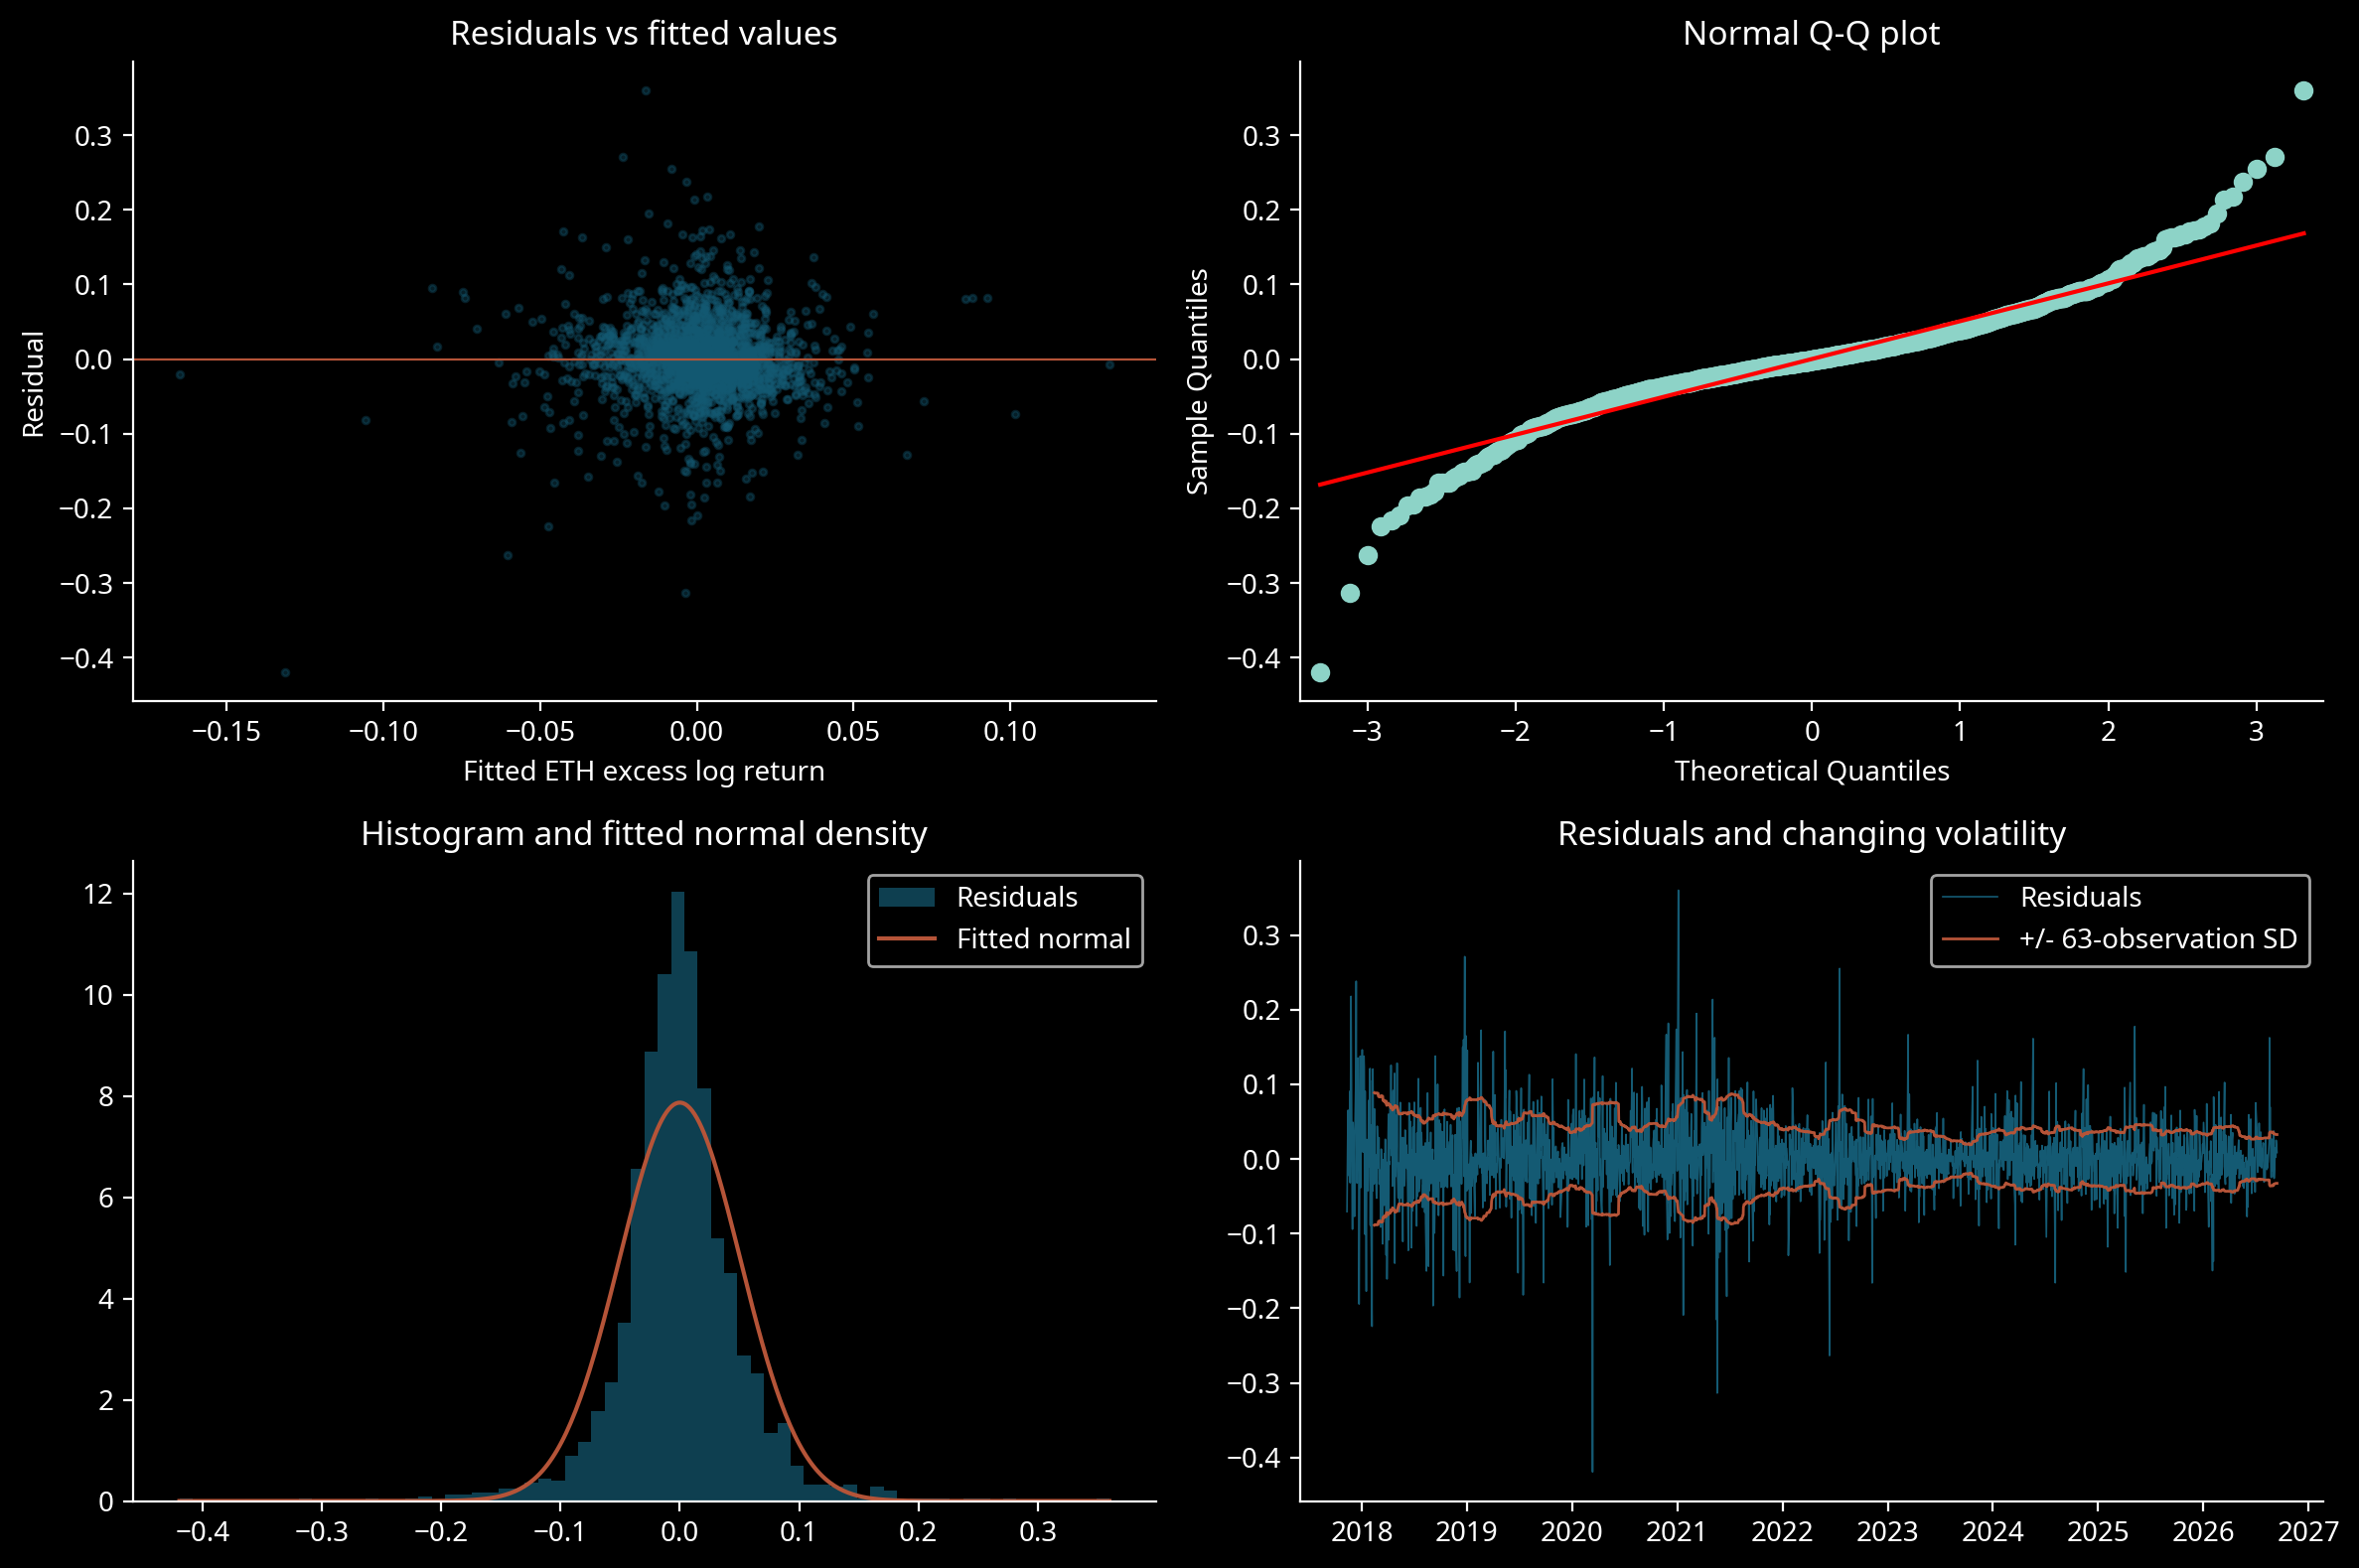

In [8]:
eps=models['ETH']['classical'].resid
fitted=models['ETH']['classical'].fittedvalues
fig,axs=plt.subplots(2,2,figsize=(12,8))
axs[0,0].scatter(fitted,eps,s=6,alpha=.35,color='#145a73');axs[0,0].axhline(0,color='#b55438',lw=.8)
axs[0,0].set_xlabel('Fitted ETH excess log return');axs[0,0].set_ylabel('Residual');axs[0,0].set_title('Residuals vs fitted values')
sm.qqplot(eps,line='s',ax=axs[0,1]);axs[0,1].set_title('Normal Q-Q plot')
axs[1,0].hist(eps,bins=70,density=True,color='#145a73',alpha=.7,label='Residuals')
grid=np.linspace(eps.min(),eps.max(),400);axs[1,0].plot(grid,stats.norm.pdf(grid,loc=eps.mean(),scale=eps.std()),color='#b55438',label='Fitted normal')
axs[1,0].set_title('Histogram and fitted normal density');axs[1,0].legend()
axs[1,1].plot(eps.index,eps,lw=.6,color='#145a73',label='Residuals')
sd=eps.rolling(63).std();axs[1,1].plot(sd,color='#b55438',lw=1,label='+/- 63-observation SD');axs[1,1].plot(-sd,color='#b55438',lw=1)
axs[1,1].set_title('Residuals and changing volatility');axs[1,1].legend()
fig.tight_layout();fig.savefig(OUTPUT/'charts'/'ETH_residual_trial.png',dpi=170);plt.show()
interpretations['fourpanel']='Panel 1, residuals vs fitted: the spread of ETH errors is not uniform across fitted values, and the Breusch-Pagan test rejects constant conditional variance at 5%.\n\nPanel 2, Q-Q: both extreme tails depart from the reference line, consistent with the rejected normality null.\n\nPanel 3, histogram: a concentrated centre and long tails fit poorly to the Gaussian density, so normal residuals are not a defensible small-sample assumption.\n\nPanel 4, time and rolling volatility: the 63-observation standard-deviation band widens during shock episodes, visually supporting the rejected squared-residual Ljung-Box null.'


Panel 1, residuals vs fitted: the spread of ETH errors is not uniform across fitted values, and the Breusch-Pagan test rejects constant conditional variance at 5%.

Panel 2, Q-Q: both extreme tails depart from the reference line, consistent with the rejected normality null.

Panel 3, histogram: a concentrated centre and long tails fit poorly to the Gaussian density, so normal residuals are not a defensible small-sample assumption.

Panel 4, time and rolling volatility: the 63-observation standard-deviation band widens during shock episodes, visually supporting the rejected squared-residual Ljung-Box null.

In [9]:
se_rows=[]
for a in ASSETS:
    for term,null in [('const',0),('MKT',0),('MKT',1)]:
        c=models[a]['classical'];h=models[a]['hac'];scale=252*100 if term=='const' else 1
        exact=np.std(c.resid)<1e-12
        tc=(c.params[term]-null)/c.bse[term] if not exact else np.nan
        th=(h.params[term]-null)/h.bse[term] if not exact else np.nan
        pc=2*stats.t.sf(abs(tc),c.df_resid);ph=2*stats.norm.sf(abs(th))
        dc=('Reject H0' if pc<.05 else 'Do not reject H0') if not exact else 'N/A: exact control'
        dh=('Reject H0' if ph<.05 else 'Do not reject H0') if not exact else 'N/A: exact control'
        se_rows.append({'asset':a,'H0':f'{term} = {null}','estimate':h.params[term]*scale,
          'classical_se':c.bse[term]*scale,'HAC_se':h.bse[term]*scale,'classical_statistic':tc,'HAC_statistic':th,
          'classical_decision':dc,'HAC_decision':dh,'classical_p':pc,'HAC_p':ph,'flip':dc!=dh})
se_comparison=pd.DataFrame(se_rows);display(se_comparison);se_comparison.to_csv(OUTPUT/'results'/'task3_classical_vs_HAC.csv',index=False)
flips=se_comparison.loc[se_comparison.flip]
interpretations['se']='Annual alpha estimates/SEs are in percentage points; market beta estimates/SEs are dimensionless. Coefficients are identical under classical and HAC covariance because the least-squares objective is unchanged. Classical p-values are displayed only to audit which conclusions would have been wrong; reported conclusions use HAC. '
interpretations['se']+=('No conclusion changes at 5% for alpha=0, market beta=0 or market beta=1 in the non-degenerate models.' if flips.empty else 'Every 5% flip: '+'; '.join(f'{r.asset}, H0: {r.H0}: {r.classical_decision} under classical inference -> {r.HAC_decision} under HAC' for r in flips.itertuples())+'.')


,asset,H0,estimate,classical_se,HAC_se,classical_statistic,HAC_statistic,classical_decision,HAC_decision,classical_p,HAC_p,flip
0,SPY,const = 0,1.932367e-11,4.109856e-13,1.161638e-12,NaN,NaN,N/A: exact control,N/A: exact control,NaN,NaN,False
1,SPY,MKT = 0,1.000000e+00,1.516759e-15,1.664699e-15,NaN,NaN,N/A: exact control,N/A: exact control,NaN,NaN,False
2,SPY,MKT = 1,1.000000e+00,1.516759e-15,1.664699e-15,NaN,NaN,N/A: exact control,N/A: exact control,NaN,NaN,False
3,EUR/USD,const = 0,-2.804463e+00,2.430607e+00,2.335361e+00,-1.153812,-1.200869,Do not reject H0,Do not reject H0,2.487019e-01,2.298020e-01,False
4,EUR/USD,MKT = 0,1.477572e-02,8.970251e-03,1.356271e-02,1.647191,1.089437,Do not reject H0,Do not reject H0,9.966079e-02,2.759613e-01,False
5,EUR/USD,MKT = 1,1.477572e-02,8.970251e-03,1.356271e-02,-109.832408,-72.642136,Reject H0,Reject H0,0.000000e+00,0.000000e+00,False
6,BTC,const = 0,1.659434e+01,2.097924e+01,2.209414e+01,0.790989,0.751074,Do not reject H0,Do not reject H0,4.290353e-01,4.526080e-01,False
7,BTC,MKT = 0,8.239091e-01,7.742472e-02,1.753681e-01,10.641422,4.698171,Reject H0,Reject H0,7.956372e-26,2.625021e-06,False
8,BTC,MKT = 1,8.239091e-01,7.742472e-02,1.753681e-01,-2.274349,-1.004122,Reject H0,Do not reject H0,2.304033e-02,3.153200e-01,True
9,GLD,const = 0,9.912134e+00,5.679961e+00,5.340735e+00,1.745106,1.855949,Do not reject H0,Do not reject H0,8.110523e-02,6.346076e-02,False


Annual alpha estimates/SEs are in percentage points; market beta estimates/SEs are dimensionless. Coefficients are identical under classical and HAC covariance because the least-squares objective is unchanged. Classical p-values are displayed only to audit which conclusions would have been wrong; reported conclusions use HAC. Every 5% flip: BTC, H0: MKT = 1: Reject H0 under classical inference -> Do not reject H0 under HAC; ETH, H0: MKT = 1: Reject H0 under classical inference -> Do not reject H0 under HAC.

## Task 4 - Stability, legality, and Eval Suite v1.0
The break-date rationale was recorded above before estimation. **Chow H0: the intercept and all three slopes are equal before and after 2020-03-11**; the decision threshold is 1%. The accompanying HAC Wald interaction test has the same joint null and provides a sensitivity check for heteroskedasticity/autocorrelation. It is not the classical Chow statistic.

Rolling market betas below are CAPM slopes (covariance/variance over 252 retained return observations); they are not partial market slopes from a rolling three-factor regression.

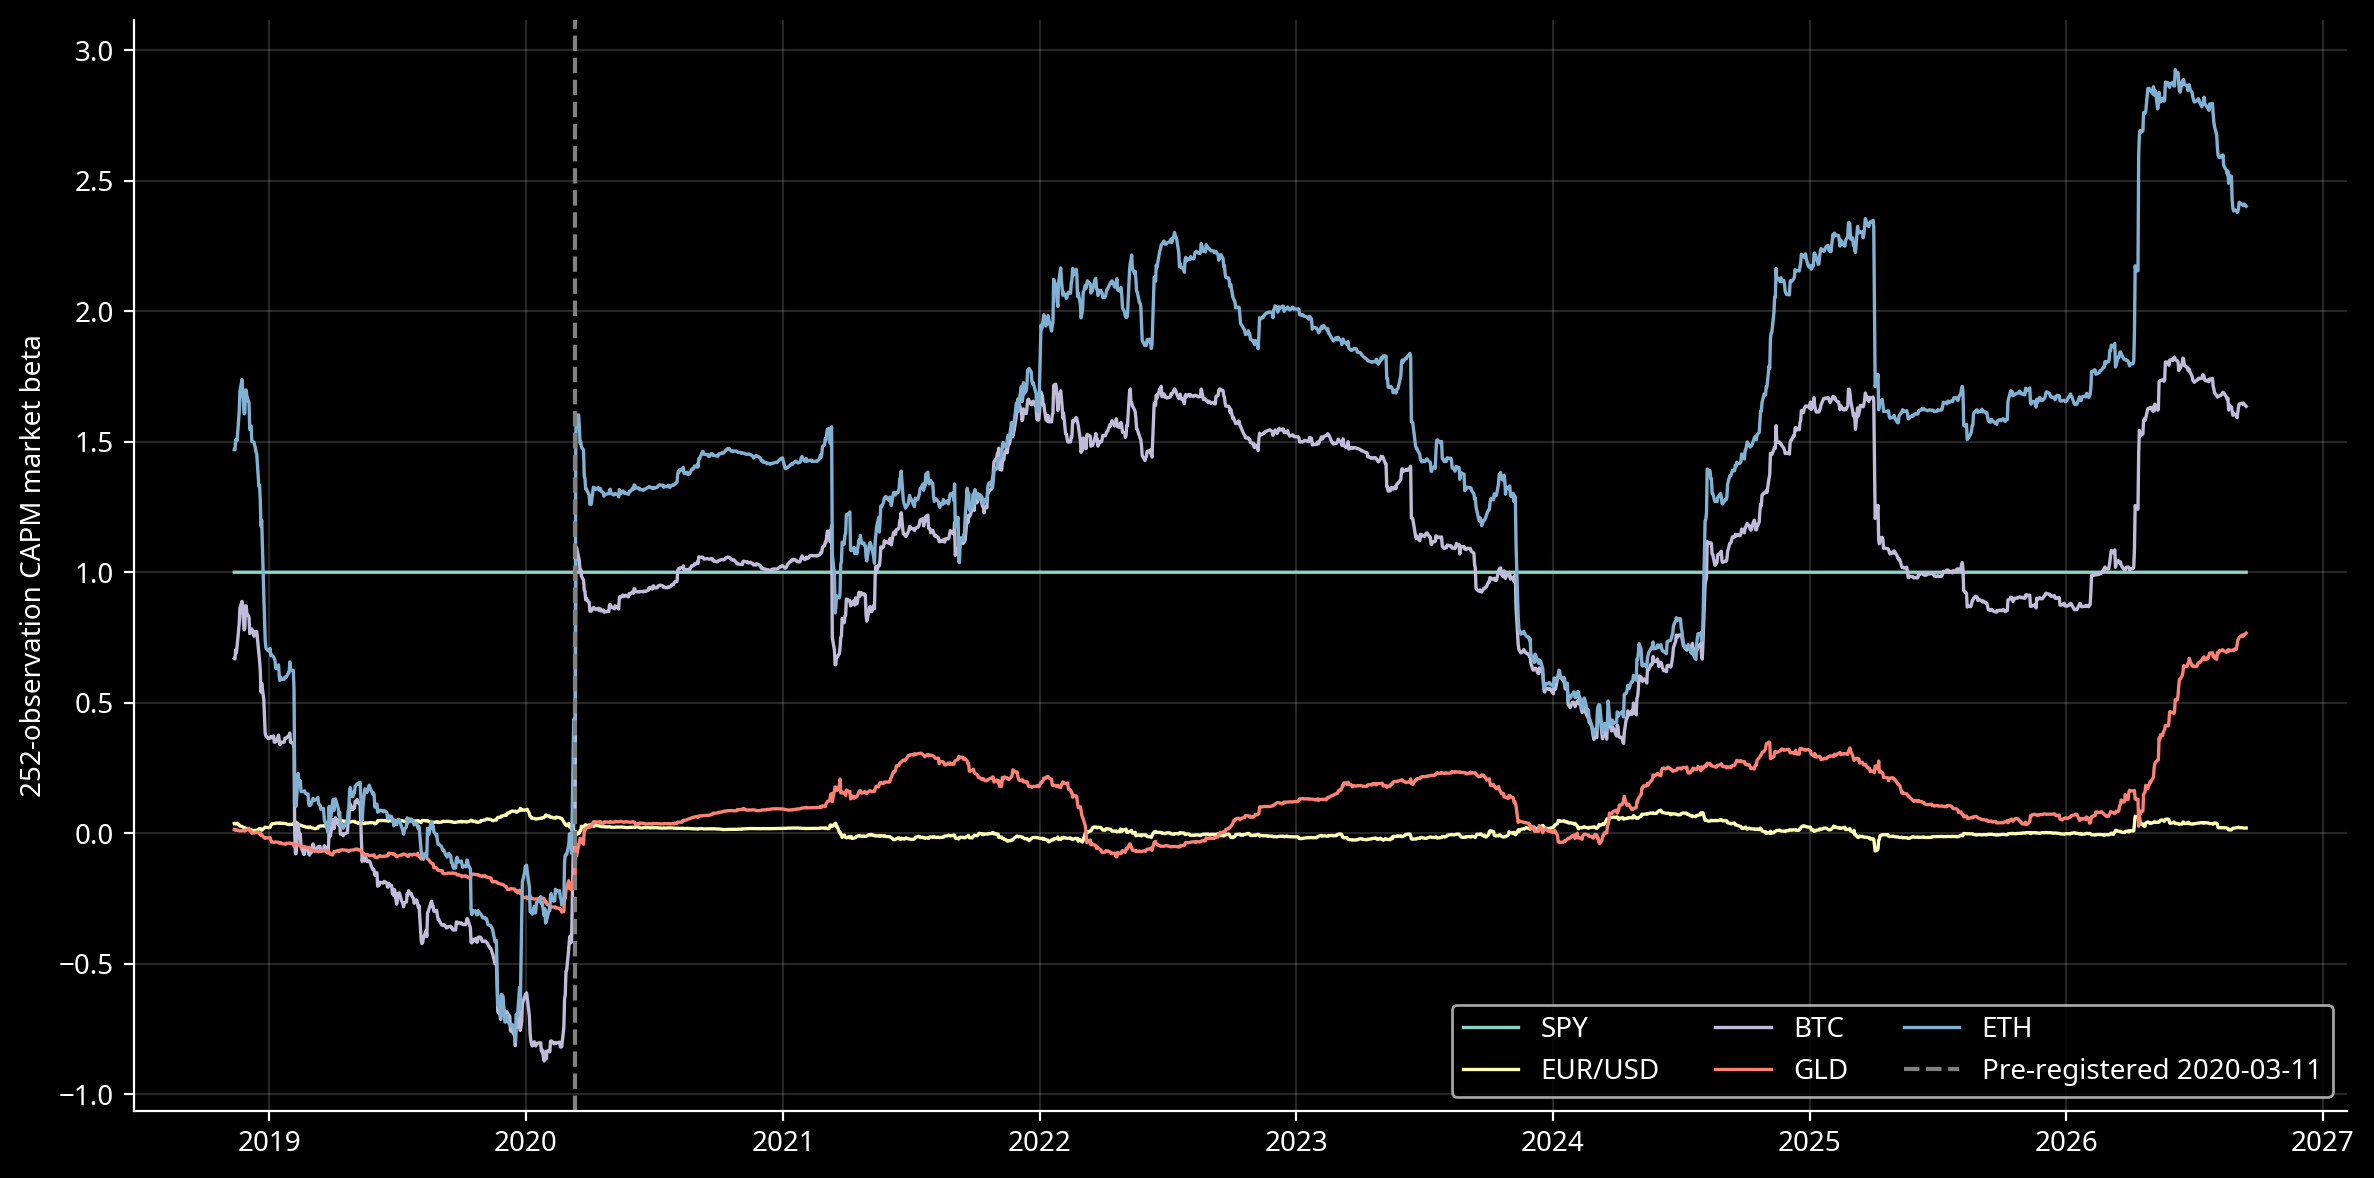

,asset,H0,Chow_F,decision_1pct,Chow_p,n_pre,n_post,df1,df2,HAC_Wald_chi2,HAC_Wald_decision_1pct,HAC_Wald_p
0,SPY,All coefficients equal across break,NaN,N/A: exact control,NaN,582,1635,4,2209,NaN,N/A: exact control,NaN
1,EUR/USD,All coefficients equal across break,0.129834,Do not reject H0,0.971574,582,1635,4,2209,0.222052,Do not reject H0,9.942744e-01
2,BTC,All coefficients equal across break,8.203397,Reject H0,0.000001,582,1635,4,2209,18.387856,Reject H0,1.036262e-03
3,GLD,All coefficients equal across break,8.257968,Reject H0,0.000001,582,1635,4,2209,46.247780,Reject H0,2.187104e-09
4,ETH,All coefficients equal across break,6.386604,Reject H0,0.000042,582,1635,4,2209,18.883405,Reject H0,8.284991e-04


,asset,period,n,lags,alpha_ann_pct,MKT,MKT_HAC_se,SMB,HML
0,SPY,pre,582,5,6.589358e-12,1.000000,1.003749e-15,-4.996004e-16,-1.179612e-16
1,SPY,post,1635,7,2.674826e-11,1.000000,2.125744e-15,1.752681e-17,1.883259e-16
2,EUR/USD,pre,582,5,-3.018399e+00,0.006597,2.872952e-02,-2.616898e-02,-9.832990e-03
3,EUR/USD,post,1635,7,-2.838969e+00,0.016451,1.600758e-02,-1.279293e-02,1.030158e-02
4,BTC,pre,582,5,6.578063e+00,0.280474,3.068263e-01,2.642992e-01,2.771600e-01
5,BTC,post,1635,7,2.012234e+01,0.989122,1.907271e-01,7.612496e-01,-5.416807e-01
6,GLD,pre,582,5,9.005663e+00,-0.114483,3.490340e-02,4.560707e-02,-2.220772e-02
7,GLD,post,1635,7,9.690318e+00,0.146725,3.171808e-02,8.020016e-02,-4.218332e-02
8,ETH,pre,582,5,-1.825372e+01,0.662262,4.091655e-01,2.945338e-01,4.097690e-01
9,ETH,post,1635,7,1.821667e+01,1.402446,2.430961e-01,8.777505e-01,-6.708648e-01


In [10]:
def chow_test(y,X,break_date=BREAK):
    pre=X.index<break_date;k=X.shape[1];n=len(X)
    if min(pre.sum(),(~pre).sum())<=k:return {'F':np.nan,'p':np.nan,'n_pre':int(pre.sum()),'n_post':int((~pre).sum()),'df1':k,'df2':n-2*k}
    course_chow=course_chow_test(y,X,break_date)
    pooled=sm.OLS(y,X).fit();m1=sm.OLS(y.loc[pre],X.loc[pre]).fit();m2=sm.OLS(y.loc[~pre],X.loc[~pre]).fit()
    rss=m1.ssr+m2.ssr
    F=max(0,float((pooled.ssr-rss)/k/(rss/(n-2*k)))) if rss>1e-20 else np.nan
    if np.isfinite(F): np.testing.assert_allclose(F,course_chow['F'],rtol=1e-10,atol=1e-10)
    return {'F':F,'p':float(stats.f.sf(F,k,n-2*k)),'n_pre':int(pre.sum()),'n_post':int((~pre).sum()),'df1':k,'df2':n-2*k}
rolling=pd.DataFrame(index=panel.index)
for a in ASSETS:
    rolling[a]=course_rolling_beta(panel[a]-panel.RF,panel.MKT,w=252)
fig,ax=plt.subplots(figsize=(12,6))
for a in ASSETS:ax.plot(rolling.index,rolling[a],label=a,lw=1.2)
ax.axvline(BREAK,color='gray',ls='--',label='Pre-registered 2020-03-11');ax.set_ylabel('252-observation CAPM market beta');ax.legend(ncol=3);ax.grid(alpha=.15)
fig.tight_layout();fig.savefig(OUTPUT/'charts'/'rolling_252_market_betas.png',dpi=170);plt.show()
rolling.to_csv(OUTPUT/'results'/'task4_rolling_betas.csv')
stability=[]
for a in ASSETS:
    d=models[a];test=chow_test(d['y'],d['X']);post=(d['X'].index>=BREAK).astype(float)
    interactions=d['X'].mul(post,axis=0).add_prefix('post_');XX=d['X'].join(interactions)
    wh=sm.OLS(d['y'],XX).fit(cov_type='HAC',cov_kwds={'maxlags':LAGS,'use_correction':True},use_t=False)
    if np.std(d['classical'].resid)<1e-12:wstat=wp=np.nan;decision='N/A: exact control'
    else:
        R=np.column_stack([np.zeros((4,4)),np.eye(4)]);w=wh.wald_test(R,scalar=True);wstat=float(w.statistic);wp=float(w.pvalue)
        decision='Reject H0' if test['p']<.01 else 'Do not reject H0'
    stability.append({'asset':a,'H0':'All coefficients equal across break','Chow_F':test['F'],'decision_1pct':decision,'Chow_p':test['p'],
       'n_pre':test['n_pre'],'n_post':test['n_post'],'df1':test['df1'],'df2':test['df2'],
       'HAC_Wald_chi2':wstat,'HAC_Wald_decision_1pct':('Reject H0' if wp<.01 else 'Do not reject H0') if np.isfinite(wp) else 'N/A: exact control','HAC_Wald_p':wp})
stability=pd.DataFrame(stability);display(stability);stability.to_csv(OUTPUT/'results'/'task4_stability_tests.csv',index=False)
texts=[]
path_notes={'SPY':'the slope stays at one by construction because SPY defines MKT.',
 'EUR/USD':'the loading remains near zero, consistent with weak US equity exposure throughout these windows.',
 'BTC':'the loading is negative around the pre-pandemic windows and rises strongly afterwards, indicating changing equity co-movement.',
 'GLD':'the early loading is modest, while the late-sample rise shows that gold did not maintain a uniformly near-zero equity exposure.',
 'ETH':'the exposure varies widely and rises above two in late windows, so the pooled beta understates some episodes of equity sensitivity.'}
for a in ASSETS:
    s=rolling[a].dropna();texts.append(f'**{a} rolling path:** first window {s.iloc[0]:.3f}, last window {s.iloc[-1]:.3f}, range [{s.min():.3f}, {s.max():.3f}]; '+path_notes[a])
for row in stability.itertuples():
    if row.asset=='SPY':
        texts.append('**SPY stability:** the market self-regression is an identity with essentially zero residual variance, so neither the Chow nor the HAC Wald reference distribution provides a meaningful empirical stability test.')
        continue
    texts.append(f'**{row.asset} stability:** {row.decision_1pct} for the pre-registered joint Chow null; F = {row.Chow_F:.3f}, p = {row.Chow_p:.4g}. HAC Wald: {row.HAC_Wald_decision_1pct}, p = {row.HAC_Wald_p:.4g}. '+('For rejected stability, report period-specific loadings rather than presenting the pooled beta as constant.' if row.Chow_p<.01 else 'Non-rejection at this single date does not establish constancy at every possible break.'))
interpretations['stability']='\n\n'.join(texts)
# Subsamples are reported for every non-control asset, avoiding unqualified pooled claims.
sub=[]
for a in ASSETS:
    for label,mask in [('pre',panel.index<BREAK),('post',panel.index>=BREAK)]:
        d=factor_model_v1(panel.loc[mask,a],panel.loc[mask,['MKT','SMB','HML','RF']])
        m=d['hac'];sub.append({'asset':a,'period':label,'n':int(m.nobs),'lags':d['lags'],'alpha_ann_pct':m.params['const']*252*100,'MKT':m.params.MKT,'MKT_HAC_se':m.bse.MKT,'SMB':m.params.SMB,'HML':m.params.HML})
subsamples=pd.DataFrame(sub);display(subsamples);subsamples.to_csv(OUTPUT/'results'/'task4_subsample_loadings.csv',index=False)


**SPY rolling path:** first window 1.000, last window 1.000, range [1.000, 1.000]; the slope stays at one by construction because SPY defines MKT.

**EUR/USD rolling path:** first window 0.037, last window 0.020, range [-0.068, 0.095]; the loading remains near zero, consistent with weak US equity exposure throughout these windows.

**BTC rolling path:** first window 0.669, last window 1.636, range [-0.873, 1.825]; the loading is negative around the pre-pandemic windows and rises strongly afterwards, indicating changing equity co-movement.

**GLD rolling path:** first window 0.014, last window 0.767, range [-0.302, 0.767]; the early loading is modest, while the late-sample rise shows that gold did not maintain a uniformly near-zero equity exposure.

**ETH rolling path:** first window 1.470, last window 2.403, range [-0.800, 2.927]; the exposure varies widely and rises above two in late windows, so the pooled beta understates some episodes of equity sensitivity.

**SPY stability:** the market self-regression is an identity with essentially zero residual variance, so neither the Chow nor the HAC Wald reference distribution provides a meaningful empirical stability test.

**EUR/USD stability:** Do not reject H0 for the pre-registered joint Chow null; F = 0.130, p = 0.9716. HAC Wald: Do not reject H0, p = 0.9943. Non-rejection at this single date does not establish constancy at every possible break.

**BTC stability:** Reject H0 for the pre-registered joint Chow null; F = 8.203, p = 1.451e-06. HAC Wald: Reject H0, p = 0.001036. For rejected stability, report period-specific loadings rather than presenting the pooled beta as constant.

**GLD stability:** Reject H0 for the pre-registered joint Chow null; F = 8.258, p = 1.311e-06. HAC Wald: Reject H0, p = 2.187e-09. For rejected stability, report period-specific loadings rather than presenting the pooled beta as constant.

**ETH stability:** Reject H0 for the pre-registered joint Chow null; F = 6.387, p = 4.158e-05. HAC Wald: Reject H0, p = 0.0008285. For rejected stability, report period-specific loadings rather than presenting the pooled beta as constant.

### Legality: BTC log price on SPY log price
**ADF H0: the tested series has a unit root**; the alternative is stationarity about a constant. Use a constant and AIC-selected augmentation lags, with a 5% decision rule. Non-rejection does not prove a unit root; it triggers the conservative course guard. Apply the same specification to log prices and log returns. Ordinary levels-regression t-values are displayed as the deliberately suspect example, with HAC t alongside them; neither rescues nonstationary levels.

Agent rule: do not report a levels regression as a valid relationship unless every stochastic variable rejects the unit-root null at 5%, or a separately validated cointegration design is available. Here use log-return differences and HAC inference.

In [11]:
logp=np.log(p[['BTC','SPY']]);logr=logp.diff().dropna()
def adf_result(s):
    v=adfuller(pd.Series(s).dropna(),regression='c',autolag='AIC')
    original=course_adf_row(pd.Series(s))
    np.testing.assert_allclose(v[:2],[original['ADF stat'],original['p-value']],atol=1e-14)
    return {'statistic':float(v[0]),'p':float(v[1]),'lags':int(v[2]),'n':int(v[3])}
adfs=[]
for label,d in [('log price',logp),('log return',logr)]:
    for a in ['BTC','SPY']:
        z=adf_result(d[a]);adfs.append({'series':f'{a} {label}','H0':'Unit root','ADF_statistic':z['statistic'],'decision_5pct':'Reject H0' if z['p']<.05 else 'Do not reject H0','p_value':z['p'],'lags_AIC':z['lags'],'n':z['n']})
adfs=pd.DataFrame(adfs);display(adfs);adfs.to_csv(OUTPUT/'results'/'task4_ADF.csv',index=False)
levels_X=sm.add_constant(logp[['SPY']]);levels_y=logp.BTC
levels_c=sm.OLS(levels_y,levels_X).fit();levels_h=sm.OLS(levels_y,levels_X).fit(cov_type='HAC',cov_kwds={'maxlags':LAGS,'use_correction':True},use_t=False)
returns_X=sm.add_constant(logr[['SPY']]);returns_h=sm.OLS(logr.BTC,returns_X).fit(cov_type='HAC',cov_kwds={'maxlags':LAGS,'use_correction':True},use_t=False)
comparison=pd.DataFrame([
 {'model':'Log price levels (suspect)','R2':levels_h.rsquared,'slope':levels_h.params.SPY,'classical_t_suspect':levels_c.tvalues.SPY,'HAC_t':levels_h.tvalues.SPY,'DW':durbin_watson(levels_h.resid),'n':int(levels_h.nobs)},
 {'model':'Log returns','R2':returns_h.rsquared,'slope':returns_h.params.SPY,'classical_t_suspect':np.nan,'HAC_t':returns_h.tvalues.SPY,'DW':durbin_watson(returns_h.resid),'n':int(returns_h.nobs)}])
display(comparison);comparison.to_csv(OUTPUT/'results'/'task4_levels_vs_returns.csv',index=False)
interpretations['legality']=f'The levels regression has R² = {levels_h.rsquared:.3f}, classical t = {levels_c.tvalues.SPY:.2f}, HAC t = {levels_h.tvalues.SPY:.2f}, and DW = {durbin_watson(levels_h.resid):.3f}. These attractive fit statistics do not override the ADF gate. In differences, R² = {returns_h.rsquared:.3f}, HAC t = {returns_h.tvalues.SPY:.2f}, and DW = {durbin_watson(returns_h.resid):.3f}. Differencing removes the common stochastic-trend mechanism; the remaining coefficient describes return co-movement rather than a price-level equilibrium. Neither ADF nor a high R² establishes causation, and the simple R² > DW heuristic is only a warning, never proof of spuriousness.'


,series,H0,ADF_statistic,decision_5pct,p_value,lags_AIC,n
0,BTC log price,Unit root,-1.117451,Do not reject H0,7.080625e-01,9,2208
1,SPY log price,Unit root,-0.351879,Do not reject H0,9.178286e-01,9,2208
2,BTC log return,Unit root,-14.706155,Reject H0,2.895252e-27,8,2208
3,SPY log return,Unit root,-14.883816,Reject H0,1.594625e-27,8,2208


,model,R2,slope,classical_t_suspect,HAC_t,DW,n
0,Log price levels (suspect),0.863966,2.618032,118.634091,36.219043,0.014337,2218
1,Log returns,0.086705,1.021324,NaN,7.204890,2.035442,2217


The levels regression has R² = 0.864, classical t = 118.63, HAC t = 36.22, and DW = 0.014. These attractive fit statistics do not override the ADF gate. In differences, R² = 0.087, HAC t = 7.20, and DW = 2.035. Differencing removes the common stochastic-trend mechanism; the remaining coefficient describes return co-movement rather than a price-level equilibrium. Neither ADF nor a high R² establishes causation, and the simple R² > DW heuristic is only a warning, never proof of spuriousness.

### Analyst Agent Eval Suite v1.0
This `audit_regression()` extends the actual course's E1-E4 logic with four additional rules, using its ADF/Chow helpers and cross-checking an execution of its original four-rule implementation on the non-degenerate models. Its alpha discipline is implemented explicitly as an implication: a significant-alpha claim is allowed only with HAC absolute t > 2; no claim is required when alpha is insignificant. A FAIL restricts a claim or flags further work; it need not prohibit estimating or displaying a model. WARN triggers review without rejecting estimation. SPY is labelled an algebraic control and its alpha/stability claims are not admissible empirical tests.

| Rule | Executable threshold | Justification |
|---|---|---|
| E1 legality | ADF p < 0.05 for y and every stochastic regressor | Conservative guard against nonstationary regression; 5% is the course's screening cutoff, not proof of stationarity. |
| E2 honest inference | covariance type == HAC | Allows changing variance and short-range dependence that classical SEs exclude. |
| E3 alpha discipline | claim alpha only if HAC absolute t > 2 and residual SD >= 1e-12 | Approximately two-sided 5% evidence; a near-zero-variance identity is not evidence of skill. |
| E4 stability | pre-registered Chow p >= 0.01; residual SD >= 1e-12 | 1% limits false alarms relative to 5%; it does not repair heteroskedasticity, so HAC Wald is also reported. |
| E5 spuriousness tripwire | R² <= DW | R² > DW is a Granger-Newbold warning; use ADF to adjudicate legality. |
| E6 sample length | n >= 504; both Chow segments >= 126 | At least two business years overall and half a year per segment limit fragile inference; these are policy thresholds, not a theorem. |
| E7 SE inflation | max HAC/classical SE <= 2; valid nonzero residual variance | A doubling is a review trigger showing material covariance sensitivity, not a universal statistical critical value. |
| E8 design hygiene | finite inputs, unique sorted dates, full rank, intercept, condition number after regressor standardization < 30 | Date/number checks prevent silent alignment failures; standardized condition number 30 flags severe collinearity without penalizing decimal units. |

E3 is an assertion about permission to claim alpha. Failing it means **do not claim skill**, not that the model should manufacture a significant intercept. Every rule produces an explicit Boolean result, status and observed value.

For SPY, E4 is labelled N/A because the exact market self-regression has no residual variance to support a Chow test. This is not a rejection of stability. The Boolean gate still declines to authorize an empirical stability claim for that identity.

In [12]:
def audit_regression(name,y,X,c,h,break_date=BREAK,claim_alpha=False):
    eps_sd=float(np.std(c.resid));exact=eps_sd<1e-12
    adfp={col:adf_result(X[col])['p'] for col in X.columns if col!='const'}
    adfp['dependent']=adf_result(y)['p']
    ch=chow_test(y,X,break_date)
    dw=float(durbin_watson(c.resid)) if not exact else np.nan
    ratio=float((h.bse/c.bse).max()) if not exact else np.nan
    stdX=X.copy()
    for col in X.columns:
        if col!='const':stdX[col]=(X[col]-X[col].mean())/X[col].std()
    cond=float(np.linalg.cond(stdX.to_numpy()))
    hygiene=bool(np.isfinite(X.to_numpy()).all() and np.isfinite(np.asarray(y)).all() and X.index.equals(y.index) and X.index.is_unique and X.index.is_monotonic_increasing and np.linalg.matrix_rank(X)==X.shape[1] and 'const' in X and cond<30)
    checks=[('E1 legality',max(adfp.values())<.05,'BLOCK',f'ADF p-values={adfp}'),
      ('E2 honest inference',h.cov_type=='HAC','BLOCK',f'cov_type={h.cov_type}'),
      ('E3 alpha discipline',(not claim_alpha) or (not exact and abs(h.tvalues['const'])>2),'CLAIM',f'claimed={claim_alpha}; HAC |t|={abs(h.tvalues["const"]):.4g}; alpha_evidence={not exact and abs(h.tvalues["const"])>2}'),
      ('E4 stability',not exact and np.isfinite(ch['p']) and ch['p']>=.01,'CLAIM',f'Chow p={ch["p"]:.4g}; exact_control={exact}'),
      ('E5 spuriousness tripwire',not exact and h.rsquared<=dw,'WARN',f'R2={h.rsquared:.4g}; DW={dw:.4g}'),
      ('E6 sample length',len(y)>=504 and min(ch['n_pre'],ch['n_post'])>=126,'BLOCK',f'n={len(y)}, pre={ch["n_pre"]}, post={ch["n_post"]}'),
      ('E7 SE inflation',not exact and ratio<=2,'WARN',f'max HAC/classical SE ratio={ratio:.4g}'),
      ('E8 design hygiene',hygiene,'BLOCK',f'standardized condition number={cond:.4g}')]
    return pd.DataFrame([{'model':name,'rule':rule,'assertion_pass':bool(ok),'status':'N/A' if exact and rule=='E4 stability' else ('PASS' if ok else ('WARN' if action=='WARN' else 'FAIL')),'scope':action,'observed':obs} for rule,ok,action,obs in checks])
print('Original course E1-E4 audit on the real non-control models (its exact function):')
for a in ASSETS:
    if a!='SPY':course_audit_regression(models[a]['y'].rename('asset_excess'),models[a]['X'].drop(columns='const'),a+' three-factor',BREAK)
course_audit_regression(levels_y.rename('log_btc'),levels_X.drop(columns='const'),'BTC on SPY levels',BREAK)
evals=pd.concat([audit_regression(a,models[a]['y'],models[a]['X'],models[a]['classical'],models[a]['hac']) for a in ASSETS]+[audit_regression('BTC on SPY log levels',levels_y,levels_X,levels_c,levels_h)],ignore_index=True)
display(evals.pivot(index='model',columns='rule',values='status'))
display(evals);evals.to_csv(OUTPUT/'results'/'task4_eval_suite.csv',index=False)
# Negative controls: the rules must reject deliberately inappropriate claims.
levels_gate=evals[(evals.model=='BTC on SPY log levels')&(evals.rule=='E1 legality')]
assert not levels_gate.assertion_pass.iloc[0], 'ADF negative control did not trigger'
classical_control=audit_regression('ETH classical covariance',models['ETH']['y'],models['ETH']['X'],models['ETH']['classical'],models['ETH']['classical'])
assert not classical_control.loc[classical_control.rule=='E2 honest inference','assertion_pass'].iloc[0]
bad_claim=audit_regression('ETH unsupported alpha claim',models['ETH']['y'],models['ETH']['X'],models['ETH']['classical'],models['ETH']['hac'],claim_alpha=True)
assert not bad_claim.loc[bad_claim.rule=='E3 alpha discipline','assertion_pass'].iloc[0]
print('Negative controls: levels legality, classical covariance and unsupported ETH alpha claim: PASS')
interpretations['eval']='The suite distinguishes whether estimation is legal from whether an analyst may claim alpha or a constant beta. E1 is the decisive gate for the levels negative control; HAC alone cannot legalize that regression. A failed E3 requires reporting the alpha interval without a skill claim. A failed E4 requires period-specific estimates and the rolling path, rather than an enduring pooled exposure. WARN under E5 or E7 prompts inspection of the other diagnostics. SPY has exact fit by construction: E4 is N/A and E5/E7 flag it as a control, while E3 passes because no skill claim is made. A passing no-claim policy does not imply a significant alpha. Passing this screen does not prove exogeneity or eliminate cross-market closing-time mismatch.'


Original course E1-E4 audit on the real non-control models (its exact function):
ANALYST AGENT — eval rules v0.1 on 'EUR/USD three-factor'   (T = 2,217, HAC lags = 7)
  ✅ PASS  E1 no unit roots among the variables
  ✅ PASS  E2 HAC standard errors reported
  ✅ PASS  E3 alpha claimed only if HAC |t| > 2
  ✅ PASS  E4 stable beta (Chow at pre-registered date, 1%)
           ↳ Chow F = 0.1 (p = 9.7e-01); β before/after = 0.01/0.02
  disclosure: adj-R² = 0.000, α = -2.80%/yr (t_HAC = -1.20), β = 0.01 (se_HAC = 0.014)
VERDICT: ACCEPTED for reporting 

ANALYST AGENT — eval rules v0.1 on 'BTC three-factor'   (T = 2,217, HAC lags = 7)
  ✅ PASS  E1 no unit roots among the variables
  ✅ PASS  E2 HAC standard errors reported
  ✅ PASS  E3 alpha claimed only if HAC |t| > 2
  ❌ FAIL  E4 stable beta (Chow at pre-registered date, 1%)
           ↳ Chow F = 8.2 (p = 1.5e-06); β before/after = 0.28/0.99
  disclosure: adj-R² = 0.103, α = +16.59%/yr (t_HAC = 0.75), β = 0.82 (se_HAC = 0.175)
VERDICT: REJECTED

rule,E1 legality,E2 honest inference,E3 alpha discipline,E4 stability,E5 spuriousness tripwire,E6 sample length,E7 SE inflation,E8 design hygiene
model,,,,,,,,
BTC,PASS,PASS,PASS,FAIL,PASS,PASS,WARN,PASS
BTC on SPY log levels,FAIL,PASS,PASS,FAIL,WARN,PASS,WARN,PASS
ETH,PASS,PASS,PASS,FAIL,PASS,PASS,WARN,PASS
EUR/USD,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
GLD,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS
SPY,PASS,PASS,PASS,N/A,WARN,PASS,WARN,PASS


,model,rule,assertion_pass,status,scope,observed
0,SPY,E1 legality,True,PASS,BLOCK,"ADF p-values={'MKT': 1.5654298435344849e-27, '..."
1,SPY,E2 honest inference,True,PASS,BLOCK,cov_type=HAC
2,SPY,E3 alpha discipline,True,PASS,CLAIM,claimed=False; HAC |t|=16.63; alpha_evidence=F...
3,SPY,E4 stability,False,N/A,CLAIM,Chow p=nan; exact_control=True
4,SPY,E5 spuriousness tripwire,False,WARN,WARN,R2=1; DW=nan
5,SPY,E6 sample length,True,PASS,BLOCK,"n=2217, pre=582, post=1635"
6,SPY,E7 SE inflation,False,WARN,WARN,max HAC/classical SE ratio=nan
7,SPY,E8 design hygiene,True,PASS,BLOCK,standardized condition number=1.723
8,EUR/USD,E1 legality,True,PASS,BLOCK,"ADF p-values={'MKT': 1.5654298435344849e-27, '..."
9,EUR/USD,E2 honest inference,True,PASS,BLOCK,cov_type=HAC


Negative controls: levels legality, classical covariance and unsupported ETH alpha claim: PASS


The suite distinguishes whether estimation is legal from whether an analyst may claim alpha or a constant beta. E1 is the decisive gate for the levels negative control; HAC alone cannot legalize that regression. A failed E3 requires reporting the alpha interval without a skill claim. A failed E4 requires period-specific estimates and the rolling path, rather than an enduring pooled exposure. WARN under E5 or E7 prompts inspection of the other diagnostics. SPY has exact fit by construction: E4 is N/A and E5/E7 flag it as a control, while E3 passes because no skill claim is made. A passing no-claim policy does not imply a significant alpha. Passing this screen does not prove exogeneity or eliminate cross-market closing-time mismatch.

### Behavioral coda
The paragraph below uses the estimated intervals, not significance stars alone.

In [13]:
g=models['GLD']['hac'];h=models['ETH']['hac'];gc=g.conf_int().loc['const']*252*100;hc=h.conf_int().loc['const']*252*100
interpretations['coda']=f'GLD has annualized three-factor alpha {g.params["const"]*252*100:.2f}% with HAC 95% interval [{gc.iloc[0]:.2f}%, {gc.iloc[1]:.2f}%], while ETH has {h.params["const"]*252*100:.2f}% with interval [{hc.iloc[0]:.2f}%, {hc.iloc[1]:.2f}%]. A fund manager prone to overconfidence can read a positive point estimate as personal skill while ignoring how wide the interval is and whether the factor exposures were stable. A client may then extrapolate that estimate into promised future outperformance even though it is conditional on this sample and this incomplete equity model. Survivorship bias strengthens the story when failed funds, delisted assets or poor track records are absent from the database. An agent trained on published winners can learn to attach the word skill to favourable intercepts without learning about the missing losers or the covariance assumptions. HAC statistics discipline uncertainty, and the measured change in alpha when SMB and HML enter shows how apparent skill can be reclassified as systematic exposure. Neither adjustment repairs survivorship bias or omitted factors by itself, so the agent must disclose universe construction and refrain from equating an unexplained return with causal skill.'


GLD has annualized three-factor alpha 9.91% with HAC 95% interval [-0.56%, 20.38%], while ETH has 8.27% with interval [-46.35%, 62.89%]. A fund manager prone to overconfidence can read a positive point estimate as personal skill while ignoring how wide the interval is and whether the factor exposures were stable. A client may then extrapolate that estimate into promised future outperformance even though it is conditional on this sample and this incomplete equity model. Survivorship bias strengthens the story when failed funds, delisted assets or poor track records are absent from the database. An agent trained on published winners can learn to attach the word skill to favourable intercepts without learning about the missing losers or the covariance assumptions. HAC statistics discipline uncertainty, and the measured change in alpha when SMB and HML enter shows how apparent skill can be reclassified as systematic exposure. Neither adjustment repairs survivorship bias or omitted factors by itself, so the agent must disclose universe construction and refrain from equating an unexplained return with causal skill.

## Optional bonus - Genuine daily Fama-French factors
Source: [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), daily three-factor CSV ZIP. The original archive is bundled. The publisher's percentage returns are divided by 100 once. The download is a direct equivalent of the `F-F_Research_Data_Factors_daily` datareader dataset.

Published factors currently end on 2026-08-31, so compare proxy and real-factor fits only on their **shared available dates**, not the longer main sample. Use simple asset returns with genuine simple-return factors and retain log returns with the notebook proxies. Use the real RF for the genuine-factor fit and proxy RF for the proxy fit; report that benchmark difference alongside portfolio-construction differences.

The comparison excludes returns whose prior price endpoint differs from the prior published factor date, avoiding a multi-day asset return paired with a one-day research factor.

In [14]:
bonus_dates=panel.index.intersection(french.index)
# Compare only intervals whose start and end dates coincide with published daily factors.
retained_previous=pd.Series(p.index,index=p.index).shift(1)
french_previous=pd.Series(french.index,index=french.index).shift(1)
matched_endpoints=retained_previous.reindex(bonus_dates).eq(french_previous.reindex(bonus_dates))
excluded_bonus_dates=bonus_dates[~matched_endpoints.to_numpy()]
bonus_dates=bonus_dates[matched_endpoints.to_numpy()]
print('Bonus dates excluded for differing endpoints:', list(excluded_bonus_dates.date))
ff=french.loc[bonus_dates,['MKT','SMB','HML','RF']]
proxy=panel.loc[bonus_dates,['MKT','SMB','HML','RF']]
correlations=pd.DataFrame([{'factor':col,'proxy_vs_original_correlation':proxy[col].corr(ff[col]),'n':len(bonus_dates)} for col in ['MKT','SMB','HML']])
display(correlations);correlations.to_csv(OUTPUT/'results'/'bonus_factor_correlations.csv',index=False)
bonus_assets=p.pct_change(fill_method=None).loc[bonus_dates]
bonus=[]
for a in ASSETS:
    for label,f in [('ETF log proxies / log assets, matched dates',proxy),('Genuine FF simple factors / simple assets, matched dates',ff)]:
        asset_returns=bonus_assets[a] if label.startswith('Genuine') else panel.loc[bonus_dates,a]
        d=factor_model_v1(asset_returns,f);m=d['hac'];ci=m.conf_int().loc['const']*252*100
        bonus.append({'asset':a,'factors':label,'n':int(m.nobs),'HAC_lags':d['lags'],'alpha_ann_pct':m.params['const']*252*100,'alpha_HAC_se_pct':m.bse['const']*252*100,'alpha_CI_low_pct':ci.iloc[0],'alpha_CI_high_pct':ci.iloc[1],'MKT':m.params.MKT,'MKT_HAC_se':m.bse.MKT,'SMB':m.params.SMB,'SMB_HAC_se':m.bse.SMB,'HML':m.params.HML,'HML_HAC_se':m.bse.HML,'R2':m.rsquared,'adj_R2':m.rsquared_adj})
bonus=pd.DataFrame(bonus);display(bonus.round(5));bonus.to_csv(OUTPUT/'results'/'bonus_real_factor_estimates.csv',index=False)
interpretations['bonus']=f'On {len(bonus_dates):,} dates with matching return endpoints, {bonus_dates.min().date()} to {bonus_dates.max().date()}, correlations of ETF proxies with genuine factors are '+', '.join(f'{z.factor}: {z.proxy_vs_original_correlation:.3f}' for z in correlations.itertuples())+'. IWM minus SPY approximates size but uses ETF index universes and weights rather than the research small-minus-big portfolio construction; IWD minus IWF similarly approximates value versus growth rather than replicating the research book-to-market sorts. The genuine market factor is a broader market portfolio than SPY, so even SPY ceases to be a perfect self-regression. The paired estimates above quantify how the exposures and unexplained mean depend on the factor construction, while different RF proxies and the return convention also contribute to alpha differences. The genuine-factor fit uses simple asset returns with simple factors; the notebook-proxy fit retains log asset returns with log spreads, avoiding mixed units within either model. Higher correlation makes a proxy useful but does not make its coefficients interchangeable with the originals.'


Bonus dates excluded for differing endpoints: [datetime.date(2017, 11, 17), datetime.date(2019, 5, 23), datetime.date(2025, 4, 22)]


,factor,proxy_vs_original_correlation,n
0,MKT,0.994692,2205
1,SMB,0.893824,2205
2,HML,0.802692,2205


,asset,factors,n,HAC_lags,alpha_ann_pct,alpha_HAC_se_pct,alpha_CI_low_pct,alpha_CI_high_pct,MKT,MKT_HAC_se,SMB,SMB_HAC_se,HML,HML_HAC_se,R2,adj_R2
0,SPY,"ETF log proxies / log assets, matched dates",2205,7,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,-0.00000,0.00000,1.00000,1.00000
1,SPY,"Genuine FF simple factors / simple assets, mat...",2205,7,-0.08763,0.37456,-0.82175,0.64650,0.98023,0.00679,-0.11757,0.00445,0.01832,0.00406,0.99408,0.99407
2,EUR/USD,"ETF log proxies / log assets, matched dates",2205,7,-2.89801,2.34096,-7.48620,1.69018,0.01495,0.01356,-0.01408,0.01490,0.00831,0.01485,0.00141,0.00005
3,EUR/USD,"Genuine FF simple factors / simple assets, mat...",2205,7,-2.75684,2.35294,-7.36851,1.85483,0.01051,0.01160,-0.00687,0.01478,-0.00546,0.01216,0.00099,-0.00037
4,BTC,"ETF log proxies / log assets, matched dates",2205,7,14.89808,22.16940,-28.55315,58.34930,0.82034,0.17603,0.74410,0.13180,-0.49433,0.14302,0.10443,0.10321
5,BTC,"Genuine FF simple factors / simple assets, mat...",2205,7,33.72549,22.19276,-9.77153,77.22251,0.88871,0.12762,0.55401,0.14363,-0.17224,0.09026,0.09546,0.09422
6,GLD,"ETF log proxies / log assets, matched dates",2205,7,10.02435,5.33248,-0.42712,20.47582,0.08448,0.02916,0.09630,0.04117,-0.05263,0.03867,0.01867,0.01733
7,GLD,"Genuine FF simple factors / simple assets, mat...",2205,7,10.93803,5.29476,0.56049,21.31556,0.09013,0.02680,0.06343,0.03852,-0.09599,0.02997,0.02438,0.02305
8,ETH,"ETF log proxies / log assets, matched dates",2205,7,7.00834,28.07282,-48.01338,62.03006,1.22442,0.22308,0.85500,0.16801,-0.59941,0.19327,0.11823,0.11703
9,ETH,"Genuine FF simple factors / simple assets, mat...",2205,7,40.61965,28.21534,-14.68141,95.92070,1.28201,0.16530,0.65052,0.18167,-0.19883,0.12518,0.10825,0.10704


On 2,205 dates with matching return endpoints, 2017-11-10 to 2026-08-31, correlations of ETF proxies with genuine factors are MKT: 0.995, SMB: 0.894, HML: 0.803. IWM minus SPY approximates size but uses ETF index universes and weights rather than the research small-minus-big portfolio construction; IWD minus IWF similarly approximates value versus growth rather than replicating the research book-to-market sorts. The genuine market factor is a broader market portfolio than SPY, so even SPY ceases to be a perfect self-regression. The paired estimates above quantify how the exposures and unexplained mean depend on the factor construction, while different RF proxies and the return convention also contribute to alpha differences. The genuine-factor fit uses simple asset returns with simple factors; the notebook-proxy fit retains log asset returns with log spreads, avoiding mixed units within either model. Higher correlation makes a proxy useful but does not make its coefficients interchangeable with the originals.

## Reproducibility and completion checklist
The input panel is unchanged from Week 2 and embedded in compressed form for offline execution. CSVs, PNG charts, source data, download provenance, the break specification and environment requirements accompany the notebook. Running all code cells regenerates the numerical exports and figures in the current working folder. The displayed written interpretations describe this frozen sample; if inputs are changed, they must be regenerated and reviewed as well.

- Task 2: both models for five assets, HAC SEs and bandwidth, chosen-asset nulls, alpha migration and asset interpretations.
- Task 3: all four diagnostic tests, failure consequences, ETH four-panel plot, classical/HAC comparison and complete flip list.
- Task 4: pre-registered break, five rolling paths, joint Chow and HAC sensitivity, ADF levels/returns, eight executable eval assertions, negative controls and behavioral coda.
- Bonus: real factors, correlations and paired estimates on matched dates.
- Task 1: actual draft source audit, eight one-at-a-time fixes on synthetic and real AAPL fixtures, corrected factor_model_v1(), seven saved Cell 8 quantity checks, independent coefficient verification and debugging log.

Original helpers are extracted from the supplied course notebook; wrappers add control-model guards, complete test statistics and upper-tail p-value precision. The eval extension uses explicit claim intent rather than requiring a nonzero alpha to pass.

The final filename is `W3_assignment_Tzalas.ipynb`.

In [15]:
(OUTPUT/'results'/'interpretations.json').write_text(json.dumps(interpretations,indent=2))
summary={'sample_n':len(panel),'sample_start':str(panel.index.min().date()),'sample_end':str(panel.index.max().date()),'HAC_lags':LAGS,'original_course_notebook_available':True,'Task1_Cell8_verified':True,'required_tasks_2_3_4_executed':True,'bonus_executed':True,'execution_errors':0}
(OUTPUT/'results'/'execution_summary.json').write_text(json.dumps(summary,indent=2))
print('All four tasks and the bonus executed. Original Cell 8 reference verified.')


All four tasks and the bonus executed. Original Cell 8 reference verified.
